# Optimal Solar Farm Siting & Capacity Allocation Across India
**Optimization course project: mathematical formulation, solution and analysis (revised)**

We have monthly NASA POWER weather and irradiance data for 960 grid cells (2020-2025). The decision is **which cells get a solar plant and how many GW to install there**, subject to a fixed capital budget, so that the energy produced is as large as possible.

We solve two versions of the same problem on the same data:

| | **Easy problem** | **Hard problem** |
|---|---|---|
| Type | Linear program (LP), convex | **Mixed-integer quadratic program (MIQP)**, concave objective + binary decisions |
| Yield | One constant performance ratio for every site | Site-specific heat and wind de-rating (daytime temperature offset, cold bonus capped) |
| Costs | Linear cost per GW | Linear cost per GW **plus a fixed grid-connection charge per plant** |
| Plant size | Any amount from 0 to the cap | Either 0 or between a minimum size and the cap |
| Risk | Ignored | **Penalises the interannual variance** of monthly generation (a mean-variance portfolio of sites); seasonal swing is handled separately by an optional firm-output constraint |

**Contents**
1. Setup and assumptions
2. Data and the India filter
3. Yield model (easy vs hard)
4. What the data says about risk (seasonal vs interannual)
5. Easy problem (LP)
6. Hard problem (MIQP) and verification
7. Easy vs hard: the price of realism (and the price of risk reduction)
8. Sensitivity analysis (budget, risk aversion, firm output, fixed cost, minimum size, thermal assumptions)
9. Additional analysis: regions, cross-evaluation, years, out-of-sample validation
10. Summary and caveats

### What changed relative to the first version
The first version penalised the variance of the *total* 72-month series. Checking it against the data showed that this variance is about 87% the repeating seasonal cycle, so the penalty was mostly "smooth the seasons" rather than "reduce uncertainty". Section 9 compares the old and new penalties directly. The six changes below follow from that.

| # | Change | Where |
|---|---|---|
| 1 | Risk split into **interannual** variance (penalised) and **seasonal** swing (separate weight $\mu$ and an optional firm-output constraint $\theta$). $\lambda$ rescaled. Std and CV reported everywhere. | §4, §6, §8 |
| 2 | Thermal model: **cold bonus capped** ($\varphi\le 1$) and an explicit **daytime temperature offset** $\delta$ (ambient data are 24-hour means). Both shown as sensitivities. | §1, §3, §8 |
| 3 | **Price of realism rewritten**: feasible comparisons only, order-independent (two-factor Shapley) decomposition, and the deliberate risk trade is reported separately. | §7 |
| 4 | **Minimum size $L$**: kept at its base value but tested over a sweep, and the text now says where it does and does not bind. | §8 |
| 5 | **Stronger verification**: tighter MIP gap, fixed-support problems solved with Clarabel, full-precision output, no swallowed exceptions, and the neighbourhood check covers **every** swap, add and drop. | §6, §8 |
| 6 | **Out-of-sample validation**: fit on three years, test on the other three (both directions). | §9 |

## 1. Setup and assumptions
Everything is self-contained. If a package is missing, run the commented line once.

**Units used throughout:** capacity $x$ in **GW**, energy in **GWh**, money in **Rs crore** (1 crore = 10 million). One GW of PV in a month delivers $\text{GHI}\,[\text{kWh/m}^2/\text{day}] \times \text{days} \times \text{PR}$ GWh, so the units work out without conversion factors.

**The cost, size, thermal-offset and risk parameters below are our modelling assumptions, not dataset values.** They set the scale of the problem. The sensitivity section (8) shows how the conclusions move when they change. Cite a source for them in the final report, or state clearly that they are assumptions.

In [1]:
# !pip install shapely pyscipopt cvxpy matplotlib pandas scipy     # run once if imports fail
import os, json, time, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import linprog
from shapely.geometry import shape, Point
from pyscipopt import Model, quicksum
import cvxpy as cp

# ---------------- file locations ----------------
CSV_CANDIDATES = ["solar_dataset.csv",
                  "dataset/solar_dataset.csv"]
DATA_CSV = next(p for p in CSV_CANDIDATES if os.path.exists(p))
BOUNDARY = "boundaries/ne_50m_admin_0_countries.geojson"      # Natural Earth country borders; downloaded if absent
BOUNDARY_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson"
os.makedirs("figures", exist_ok=True); os.makedirs("boundaries", exist_ok=True)

MONTHS = ["JAN","FEB","MAR","APR","MAY","JUN","JUL","AUG","SEP","OCT","NOV","DEC"]
DAYS = np.array([31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

# ---------------- physical assumptions ----------------
ETA0      = 0.85      # non-thermal system efficiency: soiling, inverter, wiring, mismatch, availability
GAMMA     = -0.0040   # c-Si power temperature coefficient [per degC]
U0, U1    = 25.0, 6.84  # Faiman cell-temperature model constants
SUN_HOURS = 8.0       # turns daily GHI (kWh/m2/day) into a production-weighted irradiance in W/m2
DELTA_T   = 3.0       # degC added to the 24-h mean ambient temperature to represent daytime (producing-hours) temperature
PHI_MAX   = 1.0       # cap on the thermal factor: no extrapolated efficiency bonus below 25 degC cell temperature (None = no cap)

# ---------------- economic / design assumptions ----------------
C0     = 4500.0       # variable capex, Rs crore per GW  (= Rs 4.5 crore per MW)
BUDGET = 100_000.0    # total capital budget, Rs crore    (= Rs 1 lakh crore)
UCAP   = 1.0          # per-site capacity cap, GW         (land / grid-cell limit)
FIXED  = 600.0        # fixed grid-connection cost per plant, Rs crore   (hard model only)
LMIN   = 0.2          # minimum viable plant size, GW                     (hard model only)

# ---------------- risk assumptions ----------------
LAM        = 0.3      # weight on INTERANNUAL variance: GWh of annual energy given up per GWh^2 of interannual monthly variance
MU         = 0.0      # weight on SEASONAL variance (variance of the 12-month mean profile); 0 = seasonality is not penalised
THETA      = 0.0      # firm output: every calendar month must deliver >= THETA x the average month (0 = off)
LAM_LEGACY = 0.03     # the weight the first version put on TOTAL variance (kept only for comparison)
RISK    = dict(i=LAM, s=MU, t=0.0)      # i = interannual, s = seasonal, t = total
NO_RISK = dict(i=0.0, s=0.0, t=0.0)

# same palette as the slides
NAVY, GOLD, TEAL, BLUE, GREY = "#0A2340", "#F5A623", "#0E7C86", "#16406B", "#9FB0C7"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#5B6472", "axes.labelcolor": "#2C2C2C", "font.size": 10})
print("data file:", DATA_CSV)

data file: dataset/solar_dataset.csv


## 2. Data and the India filter
The CSV has 960 grid cells × 72 months. The cells form a **rectangular box** (6.5°-37.5°N, 68.5°-97.5°E). That box contains Tibet, Pakistan, Nepal, Bangladesh, Myanmar and a lot of ocean, and the highest-irradiance cells in it are on the Tibetan plateau. An optimiser that sees all 960 cells would put solar farms in China.

We therefore keep only the cells whose **centre lies inside India's border** (Natural Earth 50 m country polygon). This is a judgement call and the only place the data is changed. Everything else comes straight from the CSV.

(69120, 13) | missing values: 0


,min,mean,max
LAT,6.50,22.00,37.50
LON,68.50,83.00,97.50
YEAR,2020.00,2022.50,2025.00
GHI,1.43,5.03,8.77
DNI,0.18,3.91,10.87
DHI,0.48,2.25,4.61
CLEARSKY_GHI,2.70,6.32,9.61
TEMPERATURE,-28.11,19.75,39.97
WIND_SPEED,0.61,3.99,11.36
RELATIVE_HUMIDITY,10.59,66.30,95.41



960 grid cells in the file, 274 of them have their centre inside India -> candidate set I = {1..274}


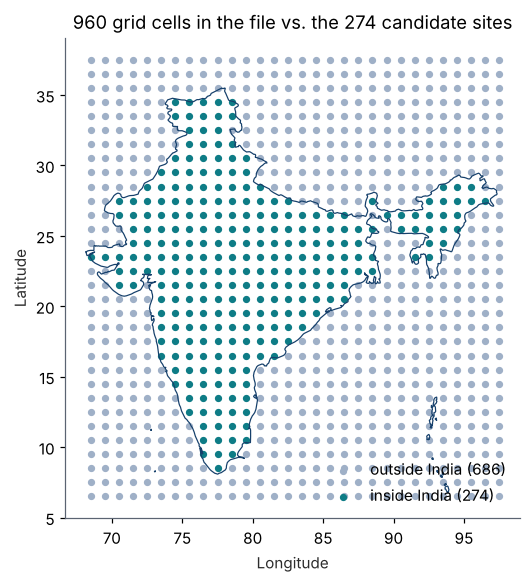

In [2]:
raw = pd.read_csv(DATA_CSV)
raw["m"] = raw.MONTH.map({m: i for i, m in enumerate(MONTHS)})
raw = raw.sort_values(["LAT", "LON", "YEAR", "m"]).reset_index(drop=True)
print(raw.shape, "| missing values:", int(raw.isna().sum().sum()))
assert raw.groupby(["LAT", "LON"]).size().eq(72).all(), "every cell must have 72 monthly rows"
display(raw.describe().T[["min", "mean", "max"]].round(2))

if not os.path.exists(BOUNDARY):
    urllib.request.urlretrieve(BOUNDARY_URL, BOUNDARY)
with open(BOUNDARY, "r", encoding="utf-8") as f:
    boundary_data = json.load(f)
india = shape([f for f in boundary_data["features"] if f["properties"].get("ADMIN") == "India"][0]["geometry"])

cells = raw[["LAT", "LON"]].drop_duplicates().reset_index(drop=True)
cells["in_india"] = [india.contains(Point(lo, la)) for la, lo in zip(cells.LAT, cells.LON)]
sites = cells[cells.in_india][["LAT", "LON"]].reset_index(drop=True)
n = len(sites)
print(f"\n{len(cells)} grid cells in the file, {n} of them have their centre inside India -> candidate set I = {{1..{n}}}")

keep_idx = pd.MultiIndex.from_frame(sites)
d = raw[raw.set_index(["LAT", "LON"]).index.isin(keep_idx)].reset_index(drop=True)
assert len(d) == n * 72
arr = lambda c: d[c].to_numpy().reshape(n, 72)       # rows = sites, columns = 72 months (year-major)
GHI, TEMP, WIND = arr("GHI"), arr("TEMPERATURE"), arr("WIND_SPEED")

def region(lat, lon):
    if lat >= 30: return "Himalayan north"
    if lat <= 17: return "South"
    if lon <= 74 and 22 <= lat <= 29: return "Rajasthan-Gujarat"
    return "Other"
ORDER = ["Rajasthan-Gujarat", "Himalayan north", "South", "Other"]
site_region = np.array([region(a, b) for a, b in zip(sites.LAT, sites.LON)])
sites["region"] = site_region
reg_gw = lambda x: {r: float(x[site_region == r].sum()) for r in ORDER}

def draw_india(ax, lw=0.8):
    for g in (india.geoms if india.geom_type == "MultiPolygon" else [india]):
        ax.plot(*g.exterior.xy, color=BLUE, lw=lw)

fig, ax = plt.subplots(figsize=(5.6, 5.4))
out = cells[~cells.in_india]
ax.scatter(out.LON, out.LAT, s=14, c=GREY, label=f"outside India ({len(out)})")
ax.scatter(sites.LON, sites.LAT, s=14, c=TEAL, label=f"inside India ({n})")
draw_india(ax); ax.set_aspect("equal"); ax.legend(loc="lower right", frameon=False)
ax.set_title(f"960 grid cells in the file vs. the {n} candidate sites"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.tight_layout(); plt.savefig("figures/fig_candidates.png", dpi=200); plt.show()

## 3. Yield model: where easy and hard differ
For every site $i$ and month $t$ ($t=1..72$, $d_t$ = days in the month) we need $e_{it}$, the energy in GWh produced per GW installed.

**Easy model.** $e_{it}^{\text{easy}} = \text{PR}\cdot \text{GHI}_{it}\cdot d_t$ with a **single constant performance ratio PR** for all sites and months. Site quality is just irradiance.

**Hard model.** Panels lose power when they are hot, and wind cools them. We estimate the cell temperature with the Faiman model and apply the standard linear temperature coefficient:

$$G_{it}=\frac{1000\,\text{GHI}_{it}}{8},\qquad T^{\text{cell}}_{it}=T_{it}+\delta+\frac{G_{it}}{U_0+U_1 v_{it}},\qquad \varphi_{it}=\min\!\big\{\varphi_{\max},\;1+\gamma\,(T^{\text{cell}}_{it}-25)\big\},\qquad e^{\text{hard}}_{it}=\eta_0\,\varphi_{it}\,\text{GHI}_{it}\,d_t$$

with $\gamma=-0.004/^\circ$C, $U_0=25$, $U_1=6.84$, $\eta_0=0.85$ ($v_{it}$ is the 10 m wind speed in the data).

Two refinements over the first version, both motivated by the dataset:
- **Daytime offset $\delta$.** NASA POWER temperature is a 24-hour mean, but panels only produce in the day, when ambient air is warmer. Without a correction the cell temperature is underestimated everywhere. The dataset has no daily maximum or minimum, so $\delta$ cannot be estimated from it; we set $\delta=3\,^\circ$C and test $0$-$8\,^\circ$C in Section 8.
- **Cap $\varphi_{\max}=1$.** In the Himalayan cells, ambient temperature falls to $-25\,^\circ$C and the linear coefficient would give up to +18% efficiency. That is an extrapolation (and ignores snow cover, ice and the 10 m wind not being module-height wind), so by default the model gives no bonus for cell temperatures below 25 °C.

**Calibration.** We set the easy model's PR to the fleet-average performance ratio of the hard model, $\text{PR}=\sum e^{\text{hard}}/\sum \text{GHI}\,d$. So the easy model is right *on average* and wrong only in *which* sites it prefers. This keeps the comparison fair: any gap between the two models comes from site-level differences and the extra constraints, not from an arbitrary scale factor.

Mean annual yield per GW: $\bar e_i = \frac{1}{6}\sum_{t=1}^{72} e_{it}$ (GWh per GW per year).

fleet-average PR used by the easy model: 0.7921
thermal factor phi (after cap): mean 0.937, min 0.864, max 1.000
cell-months where the uncapped linear model would give a cold bonus (phi>1): 1038 of 19728
yield [GWh/GW/yr]  easy: 976-1608   hard: 1026-1670
rank correlation between the two yield rankings: 0.981


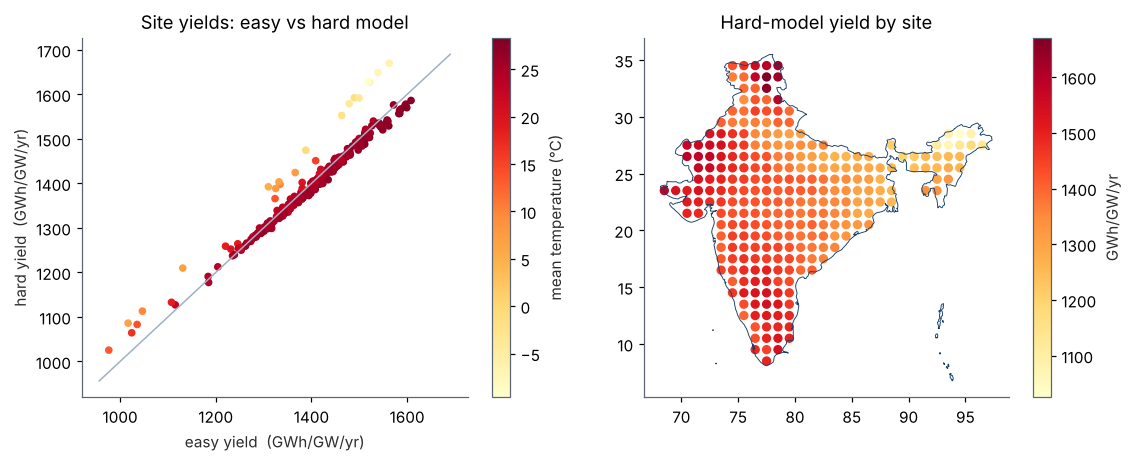

In [3]:
days72 = np.tile(DAYS, 6)[None, :]

def make_yields(delta=DELTA_T, phimax=PHI_MAX):
    """Hard-model yields e_it (GWh per GW per month), shape (n, 72), and the thermal factor phi."""
    G_op   = 1000.0 * GHI / SUN_HOURS
    T_cell = TEMP + delta + G_op / (U0 + U1 * WIND)
    phi    = 1.0 + GAMMA * (T_cell - 25.0)
    if phimax is not None: phi = np.minimum(phi, phimax)
    return ETA0 * phi * GHI * days72, phi

E_hard, phi = make_yields()
phi_raw = make_yields(phimax=None)[1]
PR_easy = E_hard.sum() / (GHI * days72).sum()
E_easy = PR_easy * GHI * days72
ebar_easy, ebar_hard = E_easy.sum(1) / 6, E_hard.sum(1) / 6

print(f"fleet-average PR used by the easy model: {PR_easy:.4f}")
print(f"thermal factor phi (after cap): mean {phi.mean():.3f}, min {phi.min():.3f}, max {phi.max():.3f}")
print(f"cell-months where the uncapped linear model would give a cold bonus (phi>1): {int((phi_raw > 1).sum())} of {phi.size}")
print(f"yield [GWh/GW/yr]  easy: {ebar_easy.min():.0f}-{ebar_easy.max():.0f}   hard: {ebar_hard.min():.0f}-{ebar_hard.max():.0f}")
print(f"rank correlation between the two yield rankings: {pd.Series(ebar_easy).corr(pd.Series(ebar_hard), method='spearman'):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.3))
sc = ax[0].scatter(ebar_easy, ebar_hard, c=TEMP.mean(1), cmap="YlOrRd", s=16)
lim = [min(ebar_easy.min(), ebar_hard.min()) - 20, max(ebar_easy.max(), ebar_hard.max()) + 20]; ax[0].plot(lim, lim, color=GREY, lw=1)
ax[0].set_xlabel("easy yield  (GWh/GW/yr)"); ax[0].set_ylabel("hard yield  (GWh/GW/yr)")
ax[0].set_title("Site yields: easy vs hard model"); plt.colorbar(sc, ax=ax[0], label="mean temperature (°C)")
sc = ax[1].scatter(sites.LON, sites.LAT, c=ebar_hard, cmap="YlOrRd", s=26); draw_india(ax[1], 0.6)
ax[1].set_aspect("equal"); ax[1].set_title("Hard-model yield by site"); plt.colorbar(sc, ax=ax[1], label="GWh/GW/yr")
plt.tight_layout(); plt.savefig("figures/fig_yield.png", dpi=200); plt.show()

## 4. What the data says about risk: seasonal vs interannual
A mean-variance model needs a risk measure that means something. The 72 monthly values of a site mix two very different things:

- the **seasonal cycle** (monsoon dip, winter dip), which repeats every year and is predictable. A grid operator can plan around it, so it is a *shape* problem, not uncertainty;
- the **interannual deviation**, how far a given month differs from the same calendar month in other years. This is the part that behaves like genuine risk.

For site $i$ let $M_{ij}$ be the mean output of calendar month $j$ over the $Y=6$ years, $s_{ij}=M_{ij}-\tfrac1{12}\sum_k M_{ik}$ the seasonal deviation, and $r_{it}=e_{it}-M_{i,j(t)}$ the interannual deviation. The two parts add up exactly: $\sum_t m_{it}^2 = Y\sum_j s_{ij}^2+\sum_t r_{it}^2$.

For a portfolio $x$:

$$V_{\text{inter}}(x)=\frac{1}{12(Y-1)}\sum_{t=1}^{72}\Big(\sum_i r_{it}x_i\Big)^2,\qquad V_{\text{seas}}(x)=\frac1{11}\sum_{j=1}^{12}\Big(\sum_i s_{ij}x_i\Big)^2$$

Both are quadratic forms $x^\top\Sigma x$ with PSD $\Sigma$. The divisor $12(Y-1)$ is the degrees of freedom left after estimating the 12 calendar-month means.

share of each site's monthly variance that is the repeating seasonal cycle: pooled 87.2%, site median 87.2%, range 24.2% to 94.6%
-> only 12.8% of the variance is year-to-year deviation, which is what behaves like risk
cold exposure: 17 of 274 candidate sites have a month with mean ambient temperature below 0 degC (coldest -25.2 degC)


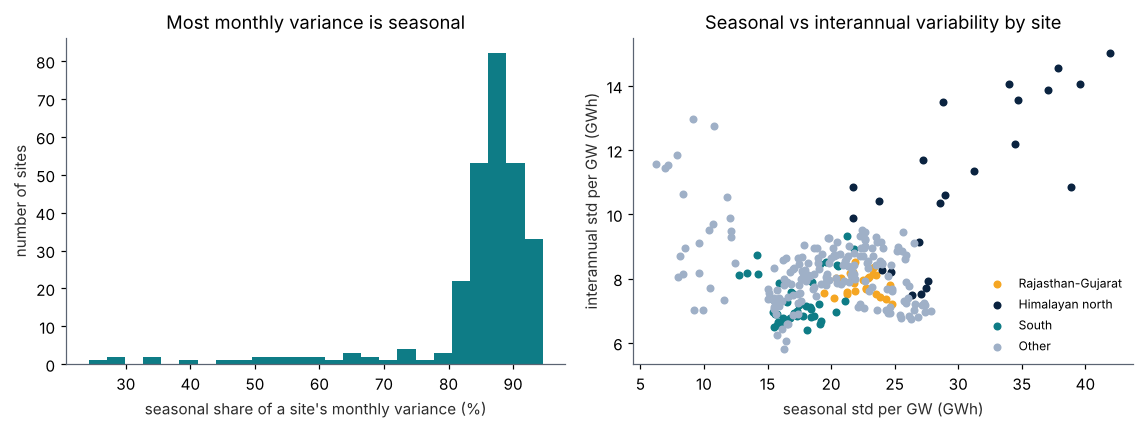

In [4]:
class RiskModel:
    """Everything the optimiser needs about one yield array E (sites x months, year-major)."""
    def __init__(self, E):
        self.E = E; self.n, self.T = E.shape; self.ny = self.T // 12
        E3 = E.reshape(self.n, self.ny, 12)
        self.ebar = E.sum(1) / self.ny                                      # GWh per GW per year
        self.M    = E3.mean(1)                                              # (n,12) mean output of each calendar month
        self.SP   = self.M - self.M.mean(1, keepdims=True)                  # (n,12) seasonal deviations s_ij
        self.RES  = (E3 - self.M[:, None, :]).reshape(self.n, self.T)       # (n,T)  interannual deviations r_it
        self.DEV  = E - E.mean(1, keepdims=True)                            # (n,T)  total deviations (first version's m_it)
        self.dof  = dict(i=12 * (self.ny - 1), s=11, t=self.T - 1)
        self.mat  = dict(i=self.RES, s=self.SP, t=self.DEV)
    def terms(self, risk):
        return [(k, self.mat[k], self.dof[k], w) for k, w in risk.items() if w > 0]
    def penalty(self, x, risk):
        return float(sum(w * np.sum((A.T @ x) ** 2) / dof for _, A, dof, w in self.terms(risk)))

RM = RiskModel(E_hard)

# exact decomposition check: total = seasonal + interannual
tot, seas, inter = (RM.DEV ** 2).sum(1), RM.ny * (RM.SP ** 2).sum(1), (RM.RES ** 2).sum(1)
assert np.allclose(tot, seas + inter), "variance decomposition failed"
share_seas = seas / tot
print(f"share of each site's monthly variance that is the repeating seasonal cycle: "
      f"pooled {seas.sum() / tot.sum():.1%}, site median {np.median(share_seas):.1%}, "
      f"range {share_seas.min():.1%} to {share_seas.max():.1%}")
print(f"-> only {1 - seas.sum() / tot.sum():.1%} of the variance is year-to-year deviation, which is what behaves like risk")
print(f"cold exposure: {int((TEMP.min(1) < 0).sum())} of {n} candidate sites have a month with mean ambient temperature below 0 degC "
      f"(coldest {TEMP.min():.1f} degC)")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4))
ax[0].hist(100 * share_seas, bins=25, color=TEAL); ax[0].set_xlabel("seasonal share of a site's monthly variance (%)"); ax[0].set_ylabel("number of sites")
ax[0].set_title("Most monthly variance is seasonal")
for r, c in zip(ORDER, [GOLD, NAVY, TEAL, GREY]):
    k = site_region == r
    if k.any(): ax[1].scatter(np.sqrt((RM.SP[k] ** 2).sum(1) / 11), np.sqrt(inter[k] / RM.dof["i"]), s=18, color=c, label=r)
ax[1].set_xlabel("seasonal std per GW (GWh)"); ax[1].set_ylabel("interannual std per GW (GWh)"); ax[1].legend(frameon=False, fontsize=8)
ax[1].set_title("Seasonal vs interannual variability by site")
plt.tight_layout(); plt.savefig("figures/fig_variance_split.png", dpi=200); plt.show()

## 5. Easy problem: a linear program
**Variables:** $x_i\ge 0$, the capacity (GW) installed at site $i$.

$$\begin{aligned}
\max_{x}\quad & \sum_{i=1}^{n} \bar e_i^{\text{easy}}\, x_i && \text{(expected annual energy)}\\
\text{s.t.}\quad & c\sum_{i} x_i \le B && \text{(budget)}\\
& 0\le x_i\le U \quad \forall i && \text{(site capacity cap)}
\end{aligned}$$

This is a **fractional knapsack**. Its optimum can be written down: rank sites by yield per rupee (all sites cost the same here, so by $\bar e_i$) and fill each to $U$ until the money runs out. We solve it with an LP solver and also verify it against that closed form. The **dual variable** of the budget constraint, $\lambda^\*$, is the energy gained per extra rupee crore of budget.

In [5]:
def solve_easy(ebar, budget=BUDGET, c0=C0, ucap=UCAP):
    k = len(ebar)
    r = linprog(-ebar, A_ub=c0 * np.ones((1, k)), b_ub=[budget], bounds=[(0, ucap)] * k, method="highs")
    assert r.status == 0
    return r.x, -r.fun, -r.ineqlin.marginals[0]          # x, objective (GWh/yr), budget dual (GWh per Rs crore)

def greedy_easy(ebar, budget=BUDGET, c0=C0, ucap=UCAP):
    x = np.zeros(len(ebar)); left = budget / c0
    for i in np.argsort(-ebar):
        x[i] = min(ucap, left); left -= x[i]
        if left <= 1e-12: break
    return x

x_easy, obj_easy, dual_easy = solve_easy(ebar_easy)
x_greedy = greedy_easy(ebar_easy)
y_easy = (x_easy > 1e-9).astype(float)
print(f"LP objective              : {obj_easy:,.4f} GWh/yr")
print(f"closed-form greedy        : {ebar_easy @ x_greedy:,.4f} GWh/yr   (max |x_LP - x_greedy| = {np.abs(x_easy - x_greedy).max():.2e})")
print(f"budget dual               : {dual_easy:.6f} GWh per Rs crore  (= marginal yield / cost = {np.sort(ebar_easy)[::-1][int(BUDGET/C0)]/C0:.6f})")
print(f"capacity {x_easy.sum():.2f} GW | sites at the cap {int((x_easy > UCAP-1e-9).sum())} | plants {int((x_easy > 1e-9).sum())}")
assert np.abs(x_easy - x_greedy).max() < 1e-6

LP objective              : 34,781.2821 GWh/yr
closed-form greedy        : 34,781.2821 GWh/yr   (max |x_LP - x_greedy| = 7.77e-16)
budget dual               : 0.339161 GWh per Rs crore  (= marginal yield / cost = 0.339161)
capacity 22.22 GW | sites at the cap 22 | plants 23


**Why this problem is "easy" and also "wrong".** It treats every GW of capacity at a site as interchangeable and free of overhead. In reality each plant needs a substation and evacuation line (a fixed cost), very small plants are not viable, hot sites lose output, and a portfolio that depends on one region has large swings in generation. The hard problem adds those layers.

## 6. Hard problem: mixed-integer quadratic program (MIQP)
**Variables:** $x_i\ge0$ (GW) and $y_i\in\{0,1\}$ ($y_i=1$ if a plant is built at site $i$).

$$\begin{aligned}
\max_{x,y}\quad & \sum_i \bar e_i^{\text{hard}}x_i\;-\;\lambda\,V_{\text{inter}}(x)\;-\;\mu\,V_{\text{seas}}(x) && \text{(energy minus risk penalties)}\\
\text{s.t.}\quad & c\sum_i x_i+F\sum_i y_i\le B && \text{(budget including fixed connection charges)}\\
& L\,y_i\le x_i\le U\,y_i\quad\forall i && \text{(build only if } x_i\ge L\text{; cap } U)\\
& \sum_i M_{ij}x_i\ \ge\ \theta\cdot\tfrac1{12}\sum_{k}\sum_i M_{ik}x_i\quad\forall j=1..12 && \text{(optional firm output; inactive when } \theta=0)\\
& y_i\in\{0,1\}
\end{aligned}$$

with $V_{\text{inter}}$ and $V_{\text{seas}}$ from Section 4. The default is $\lambda=0.3,\ \mu=0,\ \theta=0$: **only interannual variance is penalised**; seasonality is reported and can be constrained through $\mu$ or $\theta$ (Section 8).

**Why this is a MIQP.** The objective has a quadratic term and the siting decisions are binary. Because the covariance matrices are positive semidefinite the objective is **concave** (a convex problem once the binaries are relaxed), so branch-and-bound can solve it to proven optimality. The feasible set $\{0\}\cup[L,U]$ for each $x_i$ is what makes the hard problem non-convex.

**What each added layer does**
- *Heat and wind de-rating* changes which sites are best.
- *Fixed charge $F$ and minimum size $L$* link where to build with how much to build, and make many small plants unattractive. (Section 8 tests whether $L$ actually binds.)
- *Interannual variance penalty $\lambda$* is the mean-variance idea from portfolio theory applied to sites: it prefers sites whose year-to-year deviations offset each other. $\lambda=0$ removes the risk term.
- *Seasonal weight $\mu$ / firm output $\theta$* flatten the calendar-month profile, which is a separate goal from reducing risk.

**Implementation.** $\Sigma$ is dense, so each quadratic form is written with auxiliary variables $z_t=\sum_i a_{it}x_i$ and one convex quadratic constraint $\sum_t z_t^2\le \text{dof}\cdot s$, with $s$ penalised in the objective. This is the same model, much sparser. We solve it with SCIP (`pyscipopt`) to a relative gap of $10^{-6}$. Problems with the sites already fixed are convex QPs, and those are solved with Clarabel (`cvxpy`).

In [6]:
def solve_miqp(rm, risk, budget=BUDGET, c0=C0, fixed=FIXED, lmin=LMIN, ucap=UCAP, theta=0.0, time_limit=300, gap=1e-6):
    """Hard model with SCIP. Returns None if no feasible solution was found."""
    k = rm.n; m = Model(); m.hideOutput()
    m.setParam("limits/time", time_limit); m.setParam("limits/gap", gap)
    x = [m.addVar(lb=0, ub=ucap) for _ in range(k)]
    y = [m.addVar(vtype="B") for _ in range(k)]
    m.addCons(quicksum(c0 * x[i] + fixed * y[i] for i in range(k)) <= budget)
    for i in range(k):
        m.addCons(x[i] <= ucap * y[i]); m.addCons(x[i] >= lmin * y[i])
    if theta > 0:                                              # firm output: each calendar month >= theta x average month
        avg = quicksum(float(rm.M[i].mean()) * x[i] for i in range(k))
        for j in range(12):
            m.addCons(quicksum(float(rm.M[i, j]) * x[i] for i in range(k)) >= theta * avg)
    obj = quicksum(float(rm.ebar[i]) * x[i] for i in range(k))
    for _, A, dof, w in rm.terms(risk):
        nz = A.shape[1]
        z = [m.addVar(lb=-1e6, ub=1e6) for _ in range(nz)]; s = m.addVar(lb=0, ub=1e9)       # s >= variance
        for t in range(nz):
            m.addCons(z[t] == quicksum(float(A[i, t]) * x[i] for i in range(k)))
        m.addCons(quicksum(z[t] * z[t] for t in range(nz)) <= float(dof) * s)
        obj = obj - w * s
    m.setObjective(obj, "maximize")
    t0 = time.time(); m.optimize(); dt = time.time() - t0
    if m.getNSols() == 0: return None
    xv = np.array([m.getVal(v) for v in x]); yv = np.round([m.getVal(v) for v in y]); xv = np.where(yv > .5, xv, 0.0)
    pen = rm.penalty(xv, risk); en = float(rm.ebar @ xv)
    return dict(x=xv, y=yv, energy=en, pen=pen, obj=en - pen, gap=float(m.getGap()), bound=float(m.getDualbound()), time=dt)

class SupportQP:
    """Convex QP with the set of built sites fixed (solved with Clarabel). Built once, re-solved by changing parameters (DPP)."""
    def __init__(self, rm, risk, budget=BUDGET, c0=C0, fixed=FIXED, lmin=LMIN, ucap=UCAP, theta=0.0):
        self.n, self.budget, self.fixed, self.lmin, self.ucap = rm.n, budget, fixed, lmin, ucap
        self.x = cp.Variable(rm.n); self.lb = cp.Parameter(rm.n, nonneg=True); self.ub = cp.Parameter(rm.n, nonneg=True); self.rhs = cp.Parameter()
        obj = rm.ebar @ self.x
        for _, A, dof, w in rm.terms(risk): obj = obj - w * cp.sum_squares(A.T @ self.x) / dof
        cons = [c0 * cp.sum(self.x) <= self.rhs, self.x >= self.lb, self.x <= self.ub]
        if theta > 0: cons.append(rm.M.T @ self.x - theta * (rm.M.mean(1) @ self.x) >= 0)
        self.p = cp.Problem(cp.Maximize(obj), cons)
        assert self.p.is_dcp(dpp=True), "problem must be DPP so re-solves are fast"
    def solve(self, y):
        on = np.asarray(y) > .5
        rhs = self.budget - self.fixed * on.sum()
        if rhs < 0: return None, -np.inf                                     # fixed charges alone exceed the budget
        self.lb.value = np.where(on, self.lmin, 0.0); self.ub.value = np.where(on, self.ucap, 0.0); self.rhs.value = rhs
        self.p.solve(solver=cp.CLARABEL)
        if self.p.status not in ("optimal", "optimal_inaccurate"): return None, -np.inf   # infeasible (e.g. L x plants > budget)
        x = np.where(on, self.x.value, 0.0); return x, float(self.p.value)

def metrics(x, rm=None):
    """Evaluate any plan under the realistic (hard) physics; std = standard deviation of generation in GWh."""
    rm = RM if rm is None else rm
    y = x > 1e-9; month = rm.E.T @ x; prof = rm.M.T @ x; ann = month.reshape(rm.ny, 12).sum(1)
    return dict(energy=float(rm.ebar @ x), capacity=float(x.sum()), plants=int(y.sum()), cost=float(C0 * x.sum() + FIXED * y.sum()),
                std_total=float(np.sqrt(np.sum((rm.DEV.T @ x) ** 2) / rm.dof["t"])),
                std_inter=float(np.sqrt(np.sum((rm.RES.T @ x) ** 2) / rm.dof["i"])),
                std_seas=float(np.sqrt(np.sum((rm.SP.T @ x) ** 2) / rm.dof["s"])),
                cv_years_pct=float(100 * ann.std(ddof=1) / ann.mean()),
                worst_month_ratio=float(month.min() / month.mean()), worst_season_ratio=float(prof.min() / prof.mean()),
                smallest_plant=float(x[y].min()) if y.any() else 0.0)

H = solve_miqp(RM, RISK); x_hard = H["x"]; y_h = x_hard > 1e-9
mh = metrics(x_hard)
print(f"MIQP solved in {H['time']:.1f} s | objective {H['obj']:,.4f} | proven bound {H['bound']:,.4f} | relative gap {H['gap']:.1e}")
print(f"energy {H['energy']:,.1f} GWh/yr | plants {int(H['y'].sum())} | capacity {x_hard.sum():.3f} GW | smallest plant {mh['smallest_plant']:.3f} GW")
print(f"interannual std {mh['std_inter']:.1f} GWh | year-to-year CV {mh['cv_years_pct']:.2f}% | seasonal std {mh['std_seas']:.1f} GWh | worst calendar month / mean {mh['worst_season_ratio']:.3f}")

MIQP solved in 3.1 s | objective 28,594.8900 | proven bound 28,594.8900 | relative gap 0.0e+00
energy 30,206.8 GWh/yr | plants 20 | capacity 19.556 GW | smallest plant 0.724 GW
interannual std 73.3 GWh | year-to-year CV 1.14% | seasonal std 400.9 GWh | worst calendar month / mean 0.758


### Verification of the hard solution
The brief asks for verification of the optimal solutions. We check five things:
1. **Feasibility**: the budget, size and cap constraints hold on the returned solution.
2. **Optimality certificate**: SCIP's proven upper bound is within the requested gap of the objective.
3. **Independent re-solve of the continuous part**: fix the sites SCIP chose and solve the remaining convex QP with a *different* solver (Clarabel through `cvxpy`). It must reproduce SCIP's capacities and objective. This tests the capacities, not the choice of sites.
4. **No improving neighbour (local check)**: re-solve the QP for **every** single swap (one chosen site replaced by one unchosen site), every single drop and every single add. None may beat the MIQP objective by more than the solver's own gap. This is a sanity check on top of the certificate, not a proof: the certificate in step 2 is what proves optimality.
5. **Easy LP**: LP solver and closed-form greedy agree (Section 5).

Numbers are printed at full precision, and an infeasible neighbour is counted and reported rather than silently skipped.

In [7]:
# 1. feasibility
TOL = 1e-6
cost_h = C0 * x_hard.sum() + FIXED * y_h.sum()
assert cost_h <= BUDGET * (1 + TOL)
assert x_hard.max() <= UCAP + TOL and (x_hard[y_h] >= LMIN - TOL).all()
print(f"1. feasible: cost {cost_h:,.6f} <= {BUDGET:,.0f}; plant sizes in [{x_hard[y_h].min():.6f}, {x_hard.max():.6f}] GW")

# 2. certificate
print(f"2. objective {H['obj']:,.6f}  <=  proven bound {H['bound']:,.6f}   (relative gap {H['gap']:.3e})")
assert H["obj"] <= H["bound"] + 1e-6 and H["gap"] <= 1e-5

# 3. independent QP re-solve with the support fixed
qp_full = SupportQP(RM, RISK)
x_qp, obj_qp = qp_full.solve(H["y"])
print(f"3. Clarabel on the same sites: objective {obj_qp:,.6f} (diff to SCIP {abs(obj_qp - H['obj']):.3e}), max |dx| = {np.abs(x_qp - x_hard).max():.3e} GW")

# 4. full neighbourhood check: every swap, drop and add
def neighbourhood(qp, y):
    chosen, rest = np.where(y > .5)[0], np.where(y <= .5)[0]
    moves = [("swap", i, j) for i in chosen for j in rest] + [("drop", i, None) for i in chosen] + [("add", None, j) for j in rest]
    best, best_move, n_inf = -np.inf, None, 0
    for kind, i, j in moves:
        yy = y.copy()
        if i is not None: yy[i] = 0
        if j is not None: yy[j] = 1
        xx, val = qp.solve(yy)
        if xx is None: n_inf += 1; continue
        if val > best: best, best_move = val, (kind, i, j)
    return best, best_move, len(moves), n_inf

t0 = time.time()
best_nb, best_move, n_moves, n_inf = neighbourhood(qp_full, H["y"])
tol_nb = H["gap"] * abs(H["obj"]) + 1e-4
print(f"4. {n_moves} neighbours checked ({n_moves - n_inf} feasible, {n_inf} infeasible) in {time.time() - t0:.0f} s")
print(f"   best neighbour objective {best_nb:,.6f} ({best_move[0]}) vs MIQP {H['obj']:,.6f}  -> margin {H['obj'] - best_nb:.6f}"
      f"  ({'no improving neighbour' if best_nb <= H['obj'] + tol_nb else 'IMPROVING NEIGHBOUR FOUND'})")
assert best_nb <= H["obj"] + tol_nb

1. feasible: cost 100,000.000000 <= 100,000; plant sizes in [0.724101, 1.000000] GW
2. objective 28,594.889986  <=  proven bound 28,594.889986   (relative gap 0.000e+00)
3. Clarabel on the same sites: objective 28,594.889980 (diff to SCIP 6.064e-06), max |dx| = 6.976e-06 GW


4. 5354 neighbours checked (5354 feasible, 0 infeasible) in 98 s
   best neighbour objective 28,594.294169 (swap) vs MIQP 28,594.889986  -> margin 0.595818  (no improving neighbour)


## 7. Easy vs hard: the price of realism (and the price of risk reduction)
Plans are compared on equal footing by **evaluating every plan with the realistic (hard) physics**. Two questions are kept apart because the first version mixed them:

- **Price of realism**: what is lost because real yields differ from the easy model's and real plants cost more? Both layers are *constraints of the world*. Measured with the risk term switched off ($\lambda=\mu=0$).
- **Price of risk reduction**: what is given up *on purpose* by asking for lower interannual variance. That is a choice, so it is reported separately.

**Order-independent decomposition.** Two factors change between the easy and hard problems: the **yield model** (constant PR vs heat/wind physics) and the **cost model** (linear vs fixed charge plus minimum size). Each of the four combinations is optimised on its own (so re-siting is included in every corner) and its energy is read under its own yield model:

| | linear cost | fixed charge + min size |
|---|---|---|
| **easy yields** | easy LP claim | easy yields, MIQP |
| **hard yields** | hard-yield LP | hard MIQP without risk term |

The effect of each factor depends on the order in which they are switched on, so we compute both orders and report the average (the two-factor Shapley value). That average is order-independent, and the two effects add up exactly to the total.

,order 1 (yield first),order 2 (cost first),average (Shapley)
yield model: easy -> hard,277.0,269.9,273.5
cost model: linear -> fixed charge + min size,-4097.5,-4090.4,-4094.0
total (identical in every order),-3820.5,-3820.5,-3820.5


,objective,energy,capacity,plants,cost,std_total,std_inter,std_seas,cv_years_pct,worst_month_ratio,worst_season_ratio,smallest_plant
Easy LP plan,29708.108,34652.401,22.222,23.0,113800.0,464.032,128.378,465.462,1.579,0.718,0.769,0.222
"Easy sites, resized (energy only)",26203.024,29973.366,19.156,23.0,100000.0,399.603,112.106,400.443,1.571,0.723,0.772,0.200
"Easy sites, resized (full objective)",26748.944,29881.943,19.156,23.0,100000.0,387.646,102.193,390.076,1.475,0.730,0.776,0.200
"Hard, no risk term",25902.691,30960.809,19.556,20.0,100000.0,501.148,129.848,504.824,1.258,0.668,0.706,0.556
Hard MIQP,28594.890,30206.779,19.556,20.0,100000.0,392.337,73.300,400.880,1.137,0.720,0.758,0.724



Easy model claims 34,781 GWh/yr; the same plan really delivers 34,652, but costs 113,800 Rs crore with fixed charges vs a budget of 100,000.
Price of realism (no risk term)  : 3,820 GWh/yr = 11.0% of the easy claim   [yield model +273, cost model -4,094]
Price of risk reduction (chosen) : 754 GWh/yr = 2.2% of the easy claim   (year-to-year CV 1.26% -> 1.14%)
Overlap in chosen sites: 11 of 23 easy sites also appear in the hard solution (20 plants)
Value of re-siting under the full objective: hard 28,594.9 vs easy sites resized 26,748.9  (+1,845.9)


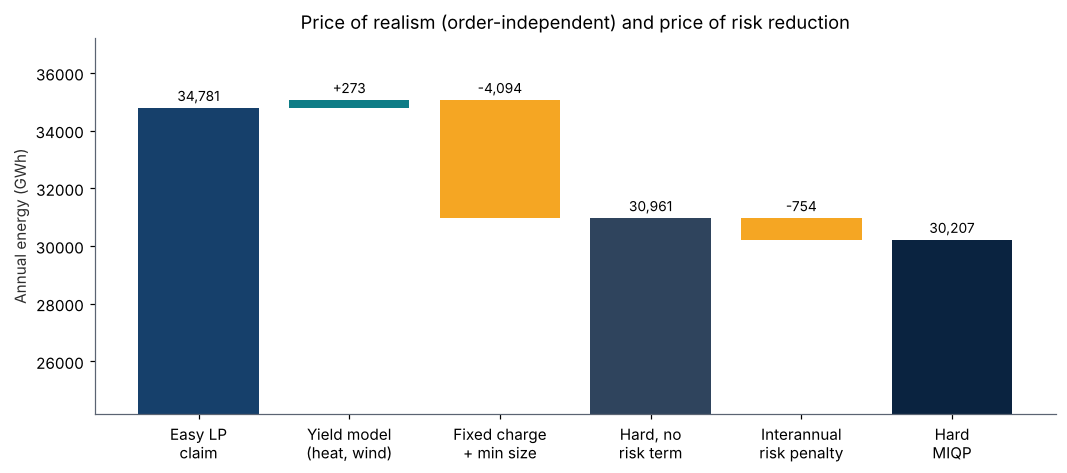

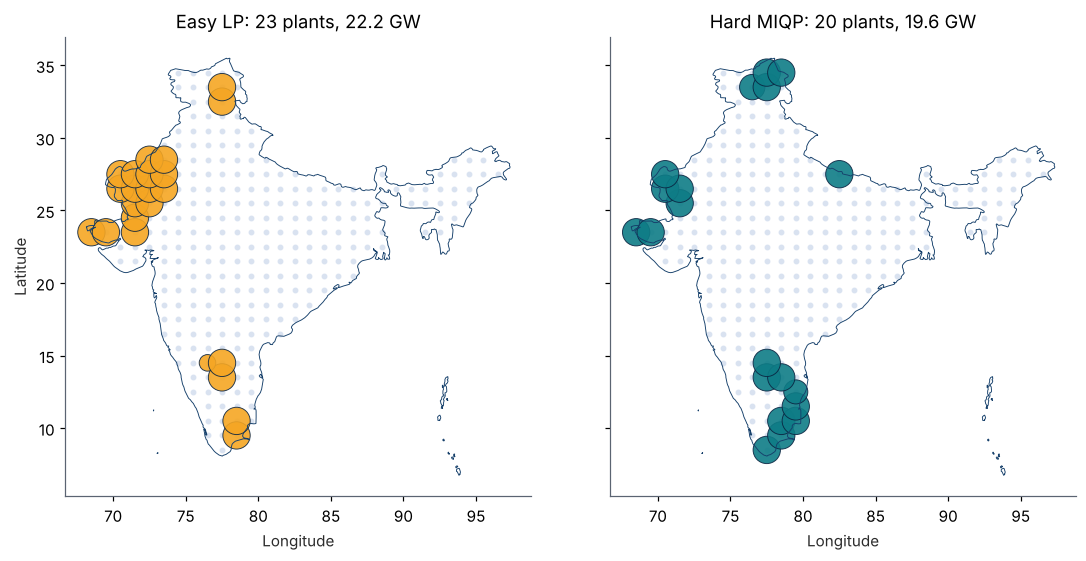

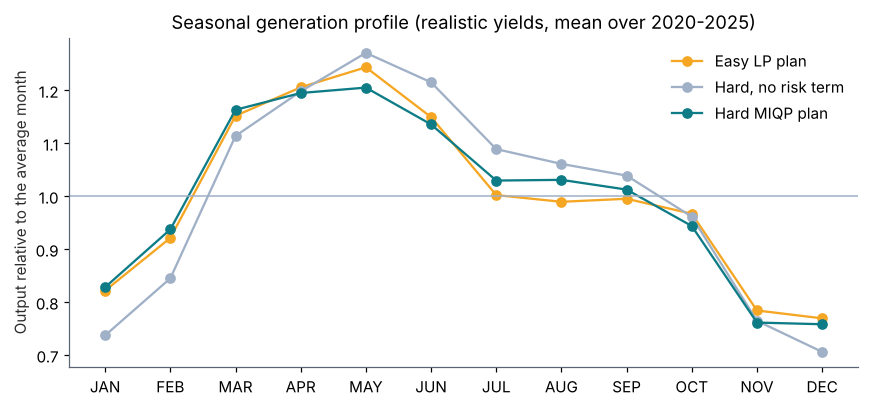

In [8]:
rm_easy = RiskModel(E_easy)
xh_lin, c_hard_lin, _ = solve_easy(ebar_hard)                  # hard yields, linear cost (LP)
Ce = solve_miqp(rm_easy, NO_RISK)                              # easy yields, fixed charge + L
D  = solve_miqp(RM, NO_RISK)                                   # hard yields, fixed charge + L, no risk term
corner = dict(easy_lin=obj_easy, hard_lin=c_hard_lin, easy_fix=Ce["energy"], hard_fix=D["energy"])

y1, c1 = corner["hard_lin"] - corner["easy_lin"], corner["hard_fix"] - corner["hard_lin"]     # order 1: yield first, then cost
c2, y2 = corner["easy_fix"] - corner["easy_lin"], corner["hard_fix"] - corner["easy_fix"]     # order 2: cost first, then yield
y_eff, c_eff = (y1 + y2) / 2, (c1 + c2) / 2
assert abs(y_eff + c_eff - (corner["hard_fix"] - corner["easy_lin"])) < 1e-6
eff = pd.DataFrame({"order 1 (yield first)": [y1, c1], "order 2 (cost first)": [y2, c2], "average (Shapley)": [y_eff, c_eff]},
                   index=["yield model: easy -> hard", "cost model: linear -> fixed charge + min size"])
eff.loc["total (identical in every order)"] = eff.sum(axis=0)
display(eff.round(1))

# plans, all evaluated with the realistic yields and costs
S_C = SupportQP(RM, NO_RISK).solve(y_easy)[0]                  # easy's sites, resized for fixed charges, energy only
S_F = SupportQP(RM, RISK).solve(y_easy)[0]                     # easy's sites, resized under the full objective
plans = {"Easy LP plan": x_easy, "Easy sites, resized (energy only)": S_C, "Easy sites, resized (full objective)": S_F,
         "Hard, no risk term": D["x"], "Hard MIQP": x_hard}
tbl = pd.DataFrame({k: metrics(v) for k, v in plans.items()}).T
tbl.insert(0, "objective", [float(RM.ebar @ v - RM.penalty(v, RISK)) for v in plans.values()])
display(tbl.round(3))

E_nr, E_h = D["energy"], H["energy"]
price_real = obj_easy - E_nr; price_risk = E_nr - E_h
print(f"\nEasy model claims {obj_easy:,.0f} GWh/yr; the same plan really delivers {RM.ebar @ x_easy:,.0f}, but costs {metrics(x_easy)['cost']:,.0f} Rs crore with fixed charges vs a budget of {BUDGET:,.0f}.")
print(f"Price of realism (no risk term)  : {price_real:,.0f} GWh/yr = {100 * price_real / obj_easy:.1f}% of the easy claim"
      f"   [yield model {y_eff:+,.0f}, cost model {c_eff:+,.0f}]")
print(f"Price of risk reduction (chosen) : {price_risk:,.0f} GWh/yr = {100 * price_risk / obj_easy:.1f}% of the easy claim"
      f"   (year-to-year CV {metrics(D['x'])['cv_years_pct']:.2f}% -> {mh['cv_years_pct']:.2f}%)")
print(f"Overlap in chosen sites: {int(((x_easy>1e-9)&(x_hard>1e-9)).sum())} of {int((x_easy>1e-9).sum())} easy sites also appear in the hard solution ({int(y_h.sum())} plants)")
print(f"Value of re-siting under the full objective: hard {H['obj']:,.1f} vs easy sites resized {RM.ebar @ S_F - RM.penalty(S_F, RISK):,.1f}"
      f"  (+{H['obj'] - (RM.ebar @ S_F - RM.penalty(S_F, RISK)):,.1f})")

# ---- waterfall: claim -> yield model -> cost model -> hard (no risk) -> risk reduction -> hard MIQP
vals = [obj_easy, obj_easy + y_eff, E_nr, E_h]; deltas = [y_eff, c_eff, -price_risk]
labels = ["Easy LP\nclaim", "Yield model\n(heat, wind)", "Fixed charge\n+ min size", "Hard, no\nrisk term", "Interannual\nrisk penalty", "Hard\nMIQP"]
fig, ax = plt.subplots(figsize=(9.8, 4.4))
ax.bar(0, obj_easy, color=BLUE); ax.text(0, obj_easy + 250, f"{obj_easy:,.0f}", ha="center", fontsize=9)
run = obj_easy
for k, dl in enumerate([y_eff, c_eff], start=1):
    ax.bar(k, abs(dl), bottom=min(run, run + dl), color=TEAL if dl > 0 else GOLD); ax.text(k, max(run, run + dl) + 250, f"{dl:+,.0f}", ha="center", fontsize=9); run += dl
ax.bar(3, E_nr, color=NAVY, alpha=.85); ax.text(3, E_nr + 250, f"{E_nr:,.0f}", ha="center", fontsize=9)
ax.bar(4, abs(price_risk), bottom=min(E_nr, E_h), color=TEAL if price_risk < 0 else GOLD); ax.text(4, E_nr + 250, f"{-price_risk:+,.0f}", ha="center", fontsize=9)
ax.bar(5, E_h, color=NAVY); ax.text(5, E_h + 250, f"{E_h:,.0f}", ha="center", fontsize=9)
ax.set_xticks(range(6)); ax.set_xticklabels(labels); ax.set_ylim(min(vals) * 0.8, obj_easy * 1.07); ax.set_ylabel("Annual energy (GWh)")
ax.set_title("Price of realism (order-independent) and price of risk reduction"); plt.tight_layout(); plt.savefig("figures/fig_waterfall.png", dpi=200); plt.show()

# ---- where the plants are
fig, ax = plt.subplots(1, 2, figsize=(10.5, 5.0), sharey=True)
for a, x, name, col in [(ax[0], x_easy, "Easy LP", GOLD), (ax[1], x_hard, "Hard MIQP", TEAL)]:
    a.scatter(sites.LON, sites.LAT, s=8, c="#D9E2F0"); draw_india(a, 0.6)
    s = x > 1e-9; a.scatter(sites.LON[s], sites.LAT[s], s=60 + 260 * x[s], c=col, edgecolor=NAVY, lw=0.6, alpha=0.9)
    a.set_aspect("equal"); a.set_title(f"{name}: {int(s.sum())} plants, {x.sum():.1f} GW"); a.set_xlabel("Longitude")
ax[0].set_ylabel("Latitude"); plt.tight_layout(); plt.savefig("figures/fig_maps.png", dpi=200); plt.show()

# ---- seasonal profile of each plan under realistic yields
prof = lambda x: (lambda o: o / o.mean())((RM.E.T @ x).reshape(6, 12).mean(0))
fig, ax = plt.subplots(figsize=(8, 3.8))
for x, nm, c in [(x_easy, "Easy LP plan", GOLD), (D["x"], "Hard, no risk term", GREY), (x_hard, "Hard MIQP plan", TEAL)]:
    ax.plot(MONTHS, prof(x), "-o", color=c, label=nm)
ax.axhline(1, color=GREY, lw=1); ax.set_ylabel("Output relative to the average month"); ax.set_title("Seasonal generation profile (realistic yields, mean over 2020-2025)")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig("figures/fig_profile.png", dpi=200); plt.show()

## 8. Sensitivity analysis
Six sweeps show how the hard solution responds to the assumptions we had to make:
- **Budget $B$**: does the gap between easy and hard persist at different scales? The easy plan is shown *repaired to the budget* (same sites, resized for fixed charges), because the raw easy plan is not affordable once connection charges are included.
- **Risk aversion $\lambda$**: the energy-versus-variability frontier, with the easy plan's sites (resized) for comparison.
- **Seasonal smoothing** ($\mu$) **and firm output** ($\theta$): what it costs to flatten the calendar-month profile, which is a different goal from reducing risk.
- **Fixed connection cost $F$**: how strongly the fixed charge drives the answer.
- **Minimum plant size $L$**: does it ever bind?
- **Thermal assumptions** ($\delta$, $\varphi_{\max}$): how much the siting depends on the temperature model.

In [9]:
sweeps = {}
reg_short = lambda x: {k.split("-")[0].split(" ")[0][:5] + "_GW": round(v, 2) for k, v in reg_gw(x).items()}

# ---- budget (energy-only comparisons are like-for-like; the risk-averse hard plan is shown alongside)
rows = []
for B in [25_000, 50_000, 75_000, 100_000, 125_000, 150_000]:
    xe, oe, _ = solve_easy(ebar_easy, budget=B)
    xr, _v = SupportQP(RM, NO_RISK, budget=B).solve(xe > 1e-9)
    hn = solve_miqp(RM, NO_RISK, budget=B); h = solve_miqp(RM, RISK, budget=B)
    rows.append(dict(B=B, easy_claimed=oe, easy_sites_repaired=float(RM.ebar @ xr), hard_no_risk=hn["energy"], hard_with_risk=h["energy"],
                     hard_plants=int(h["y"].sum()), hard_cap=float(h["x"].sum()), hard_cv_pct=metrics(h["x"])["cv_years_pct"], gap=max(h["gap"], hn["gap"])))
sb = pd.DataFrame(rows); sweeps["budget"] = rows; display(sb.round(2))

# ---- risk aversion lambda (interannual)
rows = []
for lam in [0, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0, 2.0]:
    rk = dict(i=lam, s=0.0, t=0.0)
    h = solve_miqp(RM, rk); xs, _v = SupportQP(RM, rk).solve(y_easy)
    mhh, ms = metrics(h["x"]), metrics(xs)
    rows.append(dict(lam=lam, energy=mhh["energy"], std_inter=mhh["std_inter"], cv_pct=mhh["cv_years_pct"], std_seas=mhh["std_seas"],
                     worst_season=mhh["worst_season_ratio"], plants=mhh["plants"], **reg_short(h["x"]),
                     easy_sites_energy=ms["energy"], easy_sites_cv_pct=ms["cv_years_pct"], easy_sites_std_inter=ms["std_inter"],
                     easy_sites_interior=int(((xs > LMIN + 1e-6) & (xs < UCAP - 1e-6)).sum()), gap=h["gap"]))
sl = pd.DataFrame(rows); sweeps["lambda"] = rows; display(sl.round(3))

# ---- seasonal smoothing mu (on top of the default lambda)
rows = []
for mu in [0, 0.01, 0.03, 0.1, 0.3]:
    h = solve_miqp(RM, dict(i=LAM, s=mu, t=0.0)); mhh = metrics(h["x"])
    rows.append(dict(mu=mu, energy=mhh["energy"], std_seas=mhh["std_seas"], worst_season=mhh["worst_season_ratio"], cv_pct=mhh["cv_years_pct"], std_inter=mhh["std_inter"], **reg_short(h["x"]), gap=h["gap"]))
sm = pd.DataFrame(rows); sweeps["mu"] = rows; display(sm.round(3))

# ---- firm output theta (every calendar month >= theta x average month)
rows = []
for th in [0, 0.70, 0.75, 0.80, 0.85, 0.90]:
    h = solve_miqp(RM, RISK, theta=th)
    if h is None: rows.append(dict(theta=th, energy=np.nan)); continue
    mhh = metrics(h["x"])
    rows.append(dict(theta=th, energy=mhh["energy"], worst_season=mhh["worst_season_ratio"], std_seas=mhh["std_seas"], cv_pct=mhh["cv_years_pct"], plants=mhh["plants"], **reg_short(h["x"]), gap=h["gap"]))
sf_ = pd.DataFrame(rows); sweeps["theta"] = rows; display(sf_.round(3))

# ---- fixed connection cost F
rows = []
for F in [0, 300, 600, 900, 1200]:
    h = solve_miqp(RM, RISK, fixed=F)
    rows.append(dict(F=F, energy=h["energy"], plants=int(h["y"].sum()), cap=float(h["x"].sum()), gap=h["gap"]))
sf = pd.DataFrame(rows); sweeps["fixed"] = rows; display(sf.round(2))

# ---- minimum plant size L
rows = []
for L in [0.2, 0.4, 0.6, 0.8, 1.0]:
    h = solve_miqp(RM, RISK, lmin=L)
    if h is None: rows.append(dict(L=L, energy=np.nan)); continue
    rows.append(dict(L=L, energy=h["energy"], plants=int(h["y"].sum()), cap=float(h["x"].sum()), smallest_plant=metrics(h["x"])["smallest_plant"], binds=bool(metrics(h["x"])["smallest_plant"] <= L + 1e-6), gap=h["gap"]))
sL = pd.DataFrame(rows); sweeps["lmin"] = rows; display(sL.round(3))

# ---- thermal assumptions
rows = []; base_sites = set(np.where(y_h)[0])
for dl in [0, 3, 5, 8]:
    for pm in [1.0, None]:
        Ex, _ = make_yields(delta=dl, phimax=pm); rmx = RiskModel(Ex); h = solve_miqp(rmx, RISK); mx = metrics(h["x"], rmx)
        rows.append(dict(delta_C=dl, phi_cap=("none" if pm is None else pm), energy=mx["energy"], plants=mx["plants"], sites_in_common_with_default=len(base_sites & set(np.where(h["y"] > .5)[0])),
                         cv_pct=mx["cv_years_pct"], **reg_short(h["x"]), gap=h["gap"]))
st = pd.DataFrame(rows); sweeps["thermal"] = rows; display(st.round(3))
print("largest MIP gap over all sweep solves:", max(pd.concat([d_["gap"] for d_ in [sb, sl, sm, sf_, sf, sL, st] if "gap" in d_]).max(), 0))

,B,easy_claimed,easy_sites_repaired,hard_no_risk,hard_with_risk,hard_plants,hard_cap,hard_cv_pct,gap
0,25000,8867.83,7491.59,7991.27,7742.83,5,4.89,1.13,0.0
1,50000,17608.24,15031.46,15729.57,15390.85,10,9.78,1.24,0.0
2,75000,26235.59,22558.89,23394.47,22922.70,15,14.67,1.20,0.0
3,100000,34781.28,29973.37,30960.81,30206.78,20,19.56,1.14,0.0
4,125000,43233.76,37633.49,38460.78,37245.20,25,24.44,1.09,0.0
5,150000,51646.48,44850.35,45922.22,44241.07,30,29.33,1.00,0.0


,lam,energy,std_inter,cv_pct,std_seas,worst_season,plants,Rajas_GW,Himal_GW,South_GW,Other_GW,easy_sites_energy,easy_sites_cv_pct,easy_sites_std_inter,easy_sites_interior,gap
0,0.00,30960.809,129.848,1.258,504.824,0.706,20,9.56,8.00,2.00,0.00,29973.366,1.571,112.106,1,0.0
1,0.05,30788.228,98.773,1.269,446.382,0.734,20,8.00,5.59,5.97,0.00,29962.149,1.495,104.411,1,0.0
2,0.10,30647.766,88.971,1.222,417.613,0.750,20,7.00,4.71,7.85,0.00,29962.149,1.495,104.411,1,0.0
3,0.20,30406.709,79.053,1.145,404.315,0.757,20,6.00,4.00,9.00,0.56,29910.885,1.482,102.711,1,0.0
4,0.30,30206.779,73.300,1.137,400.880,0.758,20,6.00,3.83,8.72,1.00,29881.943,1.475,102.193,2,0.0
5,0.50,29747.505,63.713,1.058,391.039,0.760,20,5.00,3.56,8.00,3.00,29874.095,1.473,102.067,1,0.0
6,1.00,29023.773,54.362,0.894,358.293,0.778,20,4.95,2.85,6.81,4.95,29870.269,1.473,102.045,1,0.0
7,2.00,28547.935,50.946,0.822,340.125,0.789,20,4.00,3.00,6.74,5.82,20989.190,1.299,64.298,5,0.0


,mu,energy,std_seas,worst_season,cv_pct,std_inter,Rajas_GW,Himal_GW,South_GW,Other_GW,gap
0,0.00,30206.779,400.880,0.758,1.137,73.300,6.00,3.83,8.72,1.00,0.0
1,0.01,29747.803,340.608,0.796,1.159,66.663,4.95,2.90,9.00,2.70,0.0
2,0.03,28850.282,270.876,0.838,1.074,63.484,3.00,2.62,9.00,4.94,0.0
3,0.10,27120.876,194.470,0.889,1.108,74.959,2.00,1.00,7.00,9.56,0.0
4,0.30,25378.278,141.942,0.917,0.972,99.533,0.00,1.00,5.00,13.56,0.0


,theta,energy,worst_season,std_seas,cv_pct,plants,Rajas_GW,Himal_GW,South_GW,Other_GW,gap
0,0.00,30206.779,0.758,400.880,1.137,20,6.00,3.83,8.72,1.00,0.0
1,0.70,30206.779,0.758,400.880,1.137,20,6.00,3.83,8.72,1.00,0.0
2,0.75,30206.779,0.758,400.880,1.137,20,6.00,3.83,8.72,1.00,0.0
3,0.80,29836.784,0.800,344.568,1.163,20,5.00,2.97,9.00,2.59,0.0
4,0.85,29133.362,0.850,295.649,1.337,20,4.00,2.00,9.61,3.94,0.0
5,0.90,27832.102,0.900,248.482,1.361,20,2.86,0.97,6.91,8.82,0.0


,F,energy,plants,cap,gap
0,0,33974.19,25,22.22,0.0
1,300,31973.74,21,20.82,0.0
2,600,30206.78,20,19.56,0.0
3,900,28490.15,19,18.42,0.0
4,1200,26956.49,18,17.42,0.0


,L,energy,plants,cap,smallest_plant,binds,gap
0,0.2,30206.779,20,19.556,0.724,False,0.0
1,0.4,30206.779,20,19.556,0.724,False,0.0
2,0.6,30206.778,20,19.556,0.724,False,0.0
3,0.8,30202.733,20,19.556,0.800,True,0.0
4,1.0,29394.359,19,19.000,1.000,True,0.0


,delta_C,phi_cap,energy,plants,sites_in_common_with_default,cv_pct,Rajas_GW,Himal_GW,South_GW,Other_GW,gap
0,0,1.0,30385.266,20,19,1.132,6.00,3.67,8.00,1.89,0.0
1,0,none,30980.815,20,18,1.144,5.00,4.56,9.00,1.00,0.0
2,3,1.0,30206.779,20,20,1.137,6.00,3.83,8.72,1.00,0.0
3,3,none,30600.960,20,18,1.144,5.00,4.58,8.97,1.00,0.0
4,5,1.0,29985.663,20,20,1.142,5.94,3.91,8.71,1.00,0.0
5,5,none,30347.842,20,18,1.144,5.00,4.60,8.95,1.00,0.0
6,8,1.0,29660.528,20,19,1.161,5.83,4.00,8.72,1.00,0.0
7,8,none,29968.350,20,18,1.144,5.00,4.63,8.92,1.00,0.0


largest MIP gap over all sweep solves: 9.963378335138917e-07


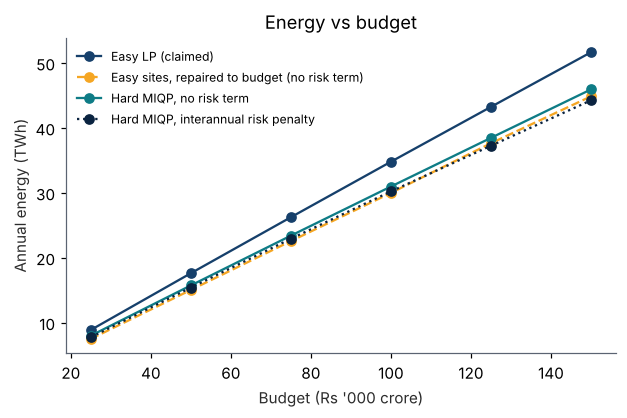

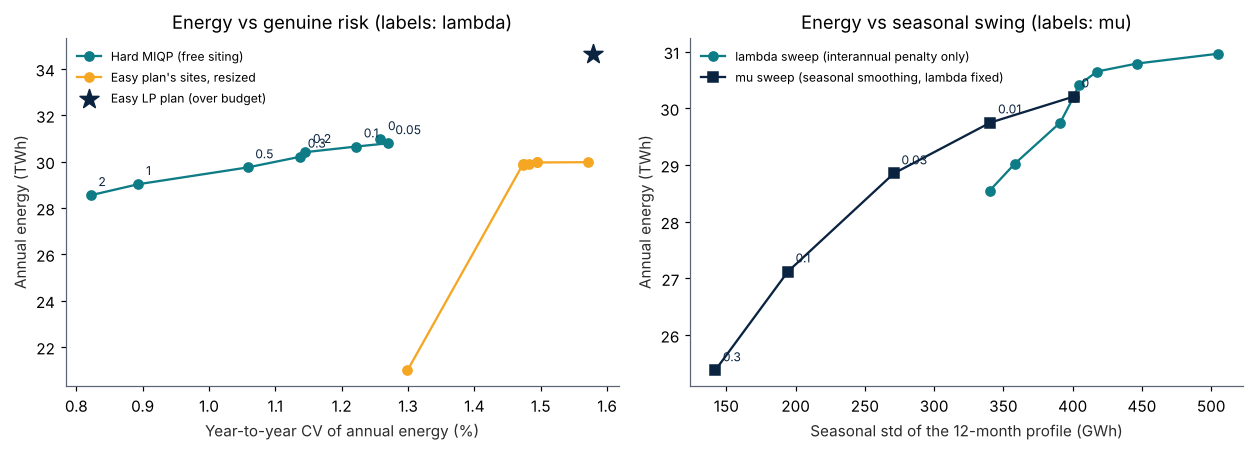

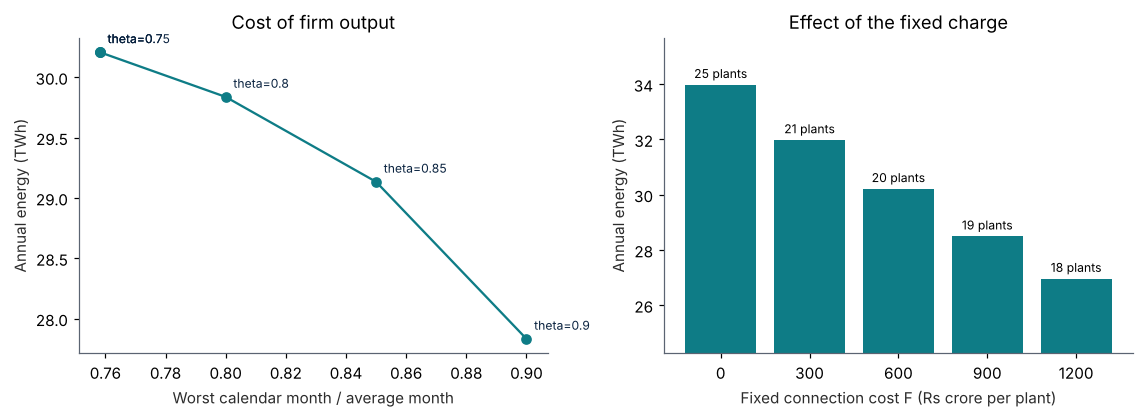

In [10]:
fig, ax = plt.subplots(figsize=(5.8, 3.9))
ax.plot(sb.B / 1000, sb.easy_claimed / 1000, "-o", color=BLUE, label="Easy LP (claimed)")
ax.plot(sb.B / 1000, sb.easy_sites_repaired / 1000, "--o", color=GOLD, label="Easy sites, repaired to budget (no risk term)")
ax.plot(sb.B / 1000, sb.hard_no_risk / 1000, "-o", color=TEAL, label="Hard MIQP, no risk term")
ax.plot(sb.B / 1000, sb.hard_with_risk / 1000, ":o", color=NAVY, label="Hard MIQP, interannual risk penalty")
ax.set_xlabel("Budget (Rs '000 crore)"); ax.set_ylabel("Annual energy (TWh)"); ax.set_title("Energy vs budget"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig_budget.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
a = ax[0]
a.plot(sl.cv_pct, sl.energy / 1000, "-o", color=TEAL, label="Hard MIQP (free siting)")
for _, r in sl.iterrows(): a.annotate(f"{r.lam:g}", (r.cv_pct, r.energy / 1000), textcoords="offset points", xytext=(5, 6), fontsize=8, color=NAVY)
a.plot(sl.easy_sites_cv_pct, sl.easy_sites_energy / 1000, "-o", color=GOLD, label="Easy plan's sites, resized")
pe = metrics(x_easy); a.scatter([pe["cv_years_pct"]], [pe["energy"] / 1000], marker="*", s=170, color=NAVY, zorder=5, label="Easy LP plan (over budget)")
a.set_xlabel("Year-to-year CV of annual energy (%)"); a.set_ylabel("Annual energy (TWh)"); a.set_title("Energy vs genuine risk (labels: lambda)"); a.legend(frameon=False, fontsize=8)
a = ax[1]
a.plot(sl.std_seas, sl.energy / 1000, "-o", color=TEAL, label="lambda sweep (interannual penalty only)")
a.plot(sm.std_seas, sm.energy / 1000, "-s", color=NAVY, label="mu sweep (seasonal smoothing, lambda fixed)")
for _, r in sm.iterrows(): a.annotate(f"{r.mu:g}", (r.std_seas, r.energy / 1000), textcoords="offset points", xytext=(5, 6), fontsize=8, color=NAVY)
a.set_xlabel("Seasonal std of the 12-month profile (GWh)"); a.set_ylabel("Annual energy (TWh)"); a.set_title("Energy vs seasonal swing (labels: mu)"); a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig_lambda.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))
ok = sf_.dropna(subset=["worst_season"])
ax[0].plot(ok.worst_season, ok.energy / 1000, "-o", color=TEAL)
for _, r in ok.iterrows(): ax[0].annotate(f"theta={r.theta:g}", (r.worst_season, r.energy / 1000), textcoords="offset points", xytext=(5, 6), fontsize=8, color=NAVY)
ax[0].set_xlabel("Worst calendar month / average month"); ax[0].set_ylabel("Annual energy (TWh)"); ax[0].set_title("Cost of firm output")
ax[1].bar(sf.F.astype(str), sf.energy / 1000, color=TEAL)
for i, r in sf.iterrows(): ax[1].text(i, r.energy / 1000 + 0.25, f"{int(r.plants)} plants", ha="center", fontsize=8)
ax[1].set_ylim(sf.energy.min() / 1000 * 0.9, sf.energy.max() / 1000 * 1.05); ax[1].set_xlabel("Fixed connection cost F (Rs crore per plant)"); ax[1].set_ylabel("Annual energy (TWh)"); ax[1].set_title("Effect of the fixed charge")
plt.tight_layout(); plt.savefig("figures/fig_firm_fixed.png", dpi=200); plt.show()

### Reading the sweeps (numbers from the delivered run)
- **Budget.** The easy claim overshoots what a plan with real costs can deliver at every budget. The hard plan *without* a risk term is 10-11% below the easy claim at each budget (at Rs 100,000 crore: 30,961 vs 34,781 GWh) and beats the easy sites repaired to the same budget by about 1 TWh (29,973 GWh), so re-siting is worth roughly 3%. Adding the interannual penalty costs a further 2-3%.
- **Risk aversion $\lambda$.** Interannual std falls steadily from 130 to 51 GWh as $\lambda$ rises from 0 to 2 and energy falls with it. The annual-total CV is not monotone at small $\lambda$ (1.26% at 0, 1.27% at 0.05, then falling to 0.82% at 2) because the penalty acts on monthly deviations, not on annual totals. The seasonal swing also falls as a by-product (505 to 401 GWh at the default), because the lower-risk sites are mostly in the South. For the easy plan's sites, the rows at $\lambda=0.05$ and $0.1$ are identical because exactly one plant is strictly between its bounds, so the budget pins its size and nothing moves until $\lambda$ is larger.
- **Seasonal smoothing $\mu$ and firm output $\theta$.** Flattening the calendar-month profile is expensive and does not reduce year-to-year risk. $\mu=0.03$ cuts seasonal std by a third (401 to 271 GWh) and costs 1,357 GWh (4.5%) with the CV unchanged. A firm-output floor of $\theta=0.85$ costs 1,073 GWh (3.6%) and *raises* the CV from 1.14% to 1.34%, because it pushes capacity out of the sunniest sites. Floors up to $\theta=0.75$ do not bind.
- **Fixed charge $F$.** This is the strongest driver: each extra Rs 300 crore per plant removes about 1,500-2,000 GWh and about one plant.
- **Minimum size $L$.** It does not bind until it exceeds the smallest plant in the solution (0.72 GW). $L=0.8$ costs 4 GWh; $L=1.0$ forces 19 full-size plants and costs 2.7%.
- **Thermal assumptions.** With the cold bonus capped, raising $\delta$ from 0 to 8 °C lowers energy by 2.4% but leaves the siting almost unchanged (19-20 of 20 sites shared with the default). Removing the cap adds about 1.3% energy, moves about 2 sites and shifts roughly 0.75 GW toward the Himalayan cells. Absolute energy therefore depends on $\delta$ and $\varphi_{\max}$, while the ranking of solutions does not.

## 9. Additional analysis: regions, cross-evaluation, years, out-of-sample validation
- **Regional mix.** Sites are grouped with simple latitude-longitude boxes (not state borders): *Rajasthan-Gujarat* (lon <= 74, 22-29 N), *Himalayan north* (lat >= 30), *South* (lat <= 17), *Other*.
- **Cross-evaluation.** Each plan is scored with both models. This shows what you would believe if you trusted the easy model, and what you would actually get.
- **Year-by-year view.** The six years are kept separate, so we can see how much each plan's annual energy moves from year to year.
- **Out-of-sample validation.** Fit each plan on three years and score it on the other three, in both directions. If the interannual penalty reduces real risk, it should reduce the *surprise* (realised minus forecast generation) on years the optimiser never saw. The first version's total-variance penalty is included for comparison. Six years is a small sample, so read this as evidence, not proof.

,Easy LP,"Hard, no risk term",Hard MIQP
Rajasthan-Gujarat,16.00,9.56,6.00
Himalayan north,2.00,8.00,3.83
South,4.22,2.00,8.72
Other,0.00,0.00,1.00


,Easy LP,"Hard, no risk term",Hard MIQP
Rajasthan-Gujarat,16,10,6
Himalayan north,2,8,4
South,5,2,9
Other,0,0,1


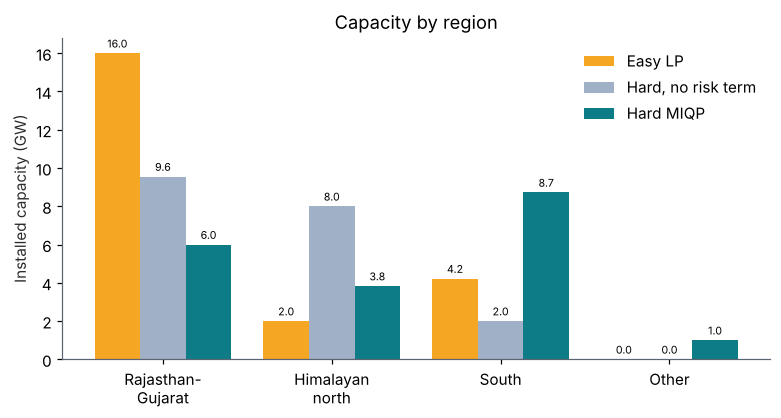

,easy_view_energy,hard_view_energy,cost_easy_view,cost_hard_view,within_budget_hard,cv_years_pct
Easy LP plan,34781.282146,34652.400821,100000.0,113800.0,False,1.579428
Hard MIQP plan,29970.79601,30206.778736,88000.0,100000.0,True,1.137254


,energy,std_inter,cv_years_pct,std_seas,worst_season_ratio
"Hard, no risk term",30960.809,129.848,1.258,504.824,0.706
Legacy total-variance penalty (lambda=0.03),29964.982,93.373,1.557,303.404,0.812
Interannual penalty (lambda=0.3),30206.779,73.300,1.137,400.880,0.758


legacy plan capacity by region (GW): {'Rajasthan-Gujarat': 3.56, 'Himalayan north': 2.0, 'South': 14.0, 'Other': 0.0}
Easy plan repaired to the budget (same sites, resized, full objective): 29,882 GWh/yr, year CV 1.47%
Hard plan: 30,207 GWh/yr, year CV 1.14%


,Easy LP plan,"Easy sites, resized","Hard, no risk term",Hard MIQP plan
2020,35370.0,30498.0,31481.0,30673.0
2021,34843.0,29981.0,30906.0,30079.0
2022,35000.0,30114.0,31173.0,30268.0
2023,34676.0,29957.0,31067.0,30493.0
2024,33961.0,29355.0,30815.0,29998.0
2025,34064.0,29387.0,30323.0,29730.0


coefficient of variation across years (%): {'Easy LP plan': 1.58, 'Easy sites, resized': 1.47, 'Hard, no risk term': 1.26, 'Hard MIQP plan': 1.14}
worst year vs the plan's own mean (%): {'Easy LP plan': -2.0, 'Easy sites, resized': -1.76, 'Hard, no risk term': -2.06, 'Hard MIQP plan': -1.58}


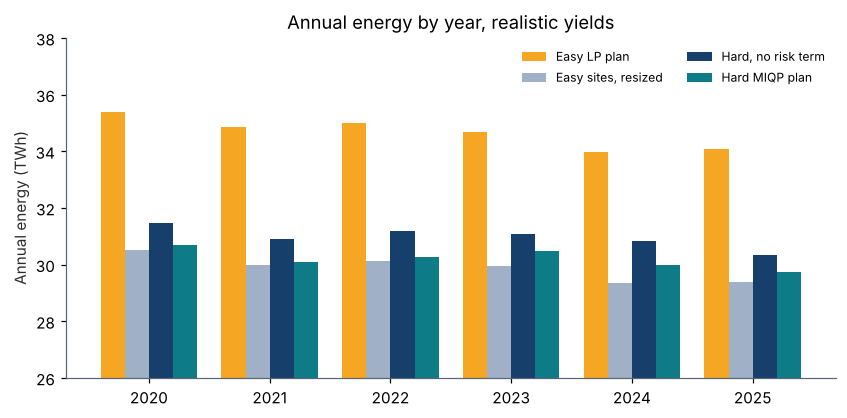

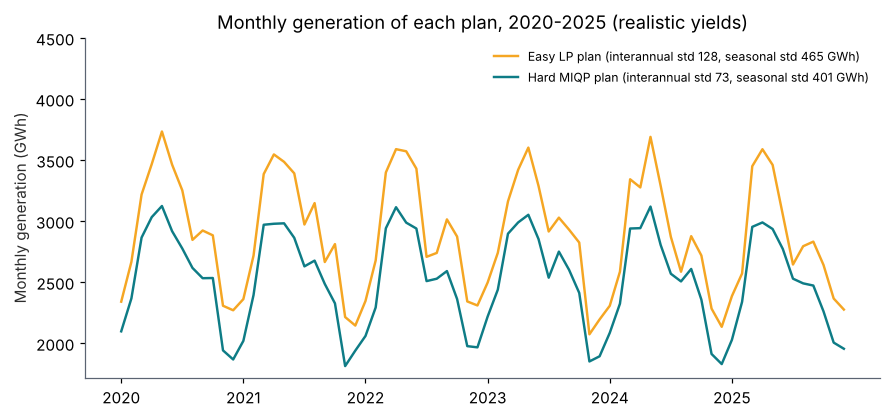

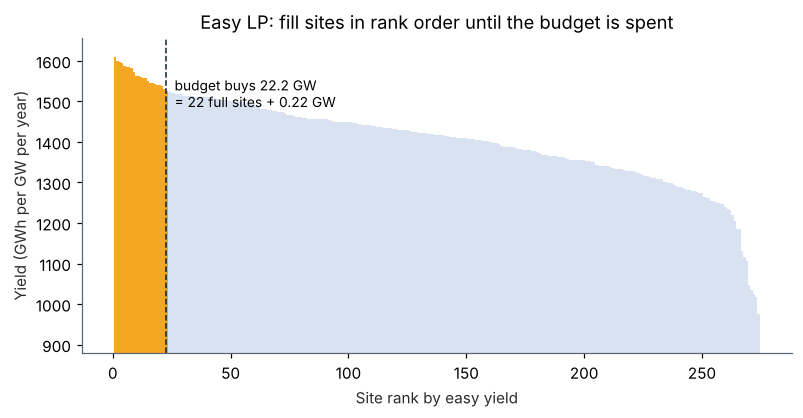

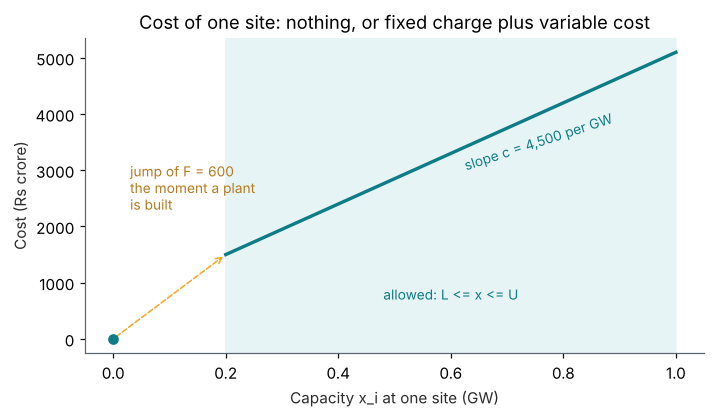

In [11]:
# ---- regional mix
reg_tab = pd.DataFrame({"Easy LP": reg_gw(x_easy), "Hard, no risk term": reg_gw(D["x"]), "Hard MIQP": reg_gw(x_hard)}).reindex(ORDER)
reg_cnt = pd.DataFrame({"Easy LP": {r: int(((x_easy > 1e-9) & (site_region == r)).sum()) for r in ORDER},
                        "Hard, no risk term": {r: int(((D["x"] > 1e-9) & (site_region == r)).sum()) for r in ORDER},
                        "Hard MIQP": {r: int(((x_hard > 1e-9) & (site_region == r)).sum()) for r in ORDER}}).reindex(ORDER)
display(reg_tab.round(2)); display(reg_cnt)
fig, ax = plt.subplots(figsize=(7.2, 3.9)); w = 0.27; xs = np.arange(len(ORDER))
for k, (c, col) in enumerate([("Easy LP", GOLD), ("Hard, no risk term", GREY), ("Hard MIQP", TEAL)]):
    ax.bar(xs + (k - 1) * w, reg_tab[c], w, color=col, label=c)
    for i, r in enumerate(ORDER): ax.text(i + (k - 1) * w, reg_tab.loc[r, c] + 0.3, f"{reg_tab.loc[r, c]:.1f}", ha="center", fontsize=7)
ax.set_xticks(xs); ax.set_xticklabels([o.replace("-", "-\n") if o == "Rajasthan-Gujarat" else o.replace(" ", "\n") for o in ORDER]); ax.set_ylabel("Installed capacity (GW)")
ax.set_title("Capacity by region"); ax.legend(frameon=False); plt.tight_layout(); plt.savefig("figures/fig_regions.png", dpi=200); plt.show()

# ---- cross-evaluation: score each plan with both models
cross = {}
for name, x in [("Easy LP plan", x_easy), ("Hard MIQP plan", x_hard)]:
    cost_hard = float(C0 * x.sum() + FIXED * (x > 1e-9).sum())
    cross[name] = dict(easy_view_energy=float(ebar_easy @ x), hard_view_energy=float(ebar_hard @ x), cost_easy_view=float(C0 * x.sum()),
                       cost_hard_view=cost_hard, within_budget_hard=bool(cost_hard <= BUDGET * (1 + 1e-6)), cv_years_pct=metrics(x)["cv_years_pct"])
display(pd.DataFrame(cross).T.round(2))
# ---- the first version's penalty (total variance) vs the interannual penalty, same data and yields
Lg = solve_miqp(RM, dict(i=0.0, s=0.0, t=LAM_LEGACY)); x_legacy = Lg["x"]
leg = pd.DataFrame({"Hard, no risk term": metrics(D["x"]), f"Legacy total-variance penalty (lambda={LAM_LEGACY})": metrics(x_legacy),
                    f"Interannual penalty (lambda={LAM})": metrics(x_hard)}).T[["energy", "std_inter", "cv_years_pct", "std_seas", "worst_season_ratio"]]
display(leg.round(3)); print("legacy plan capacity by region (GW):", {k: round(v, 2) for k, v in reg_gw(x_legacy).items()})
rep = metrics(S_F)
print(f"Easy plan repaired to the budget (same sites, resized, full objective): {rep['energy']:,.0f} GWh/yr, year CV {rep['cv_years_pct']:.2f}%")
print(f"Hard plan: {H['energy']:,.0f} GWh/yr, year CV {mh['cv_years_pct']:.2f}%")

# ---- year-by-year view (realistic yields, each calendar year separately)
YEARS = list(range(2020, 2026))
yearly = {nm: (RM.E.T @ x).reshape(6, 12).sum(axis=1) for nm, x in
          [("Easy LP plan", x_easy), ("Easy sites, resized", S_F), ("Hard, no risk term", D["x"]), ("Hard MIQP plan", x_hard)]}
ytab = pd.DataFrame(yearly, index=YEARS); display(ytab.round(0))
cv_years = {k: float(100 * v.std(ddof=1) / v.mean()) for k, v in yearly.items()}
worst_year = {k: float(100 * (v.min() / v.mean() - 1)) for k, v in yearly.items()}
print("coefficient of variation across years (%):", {k: round(v, 2) for k, v in cv_years.items()})
print("worst year vs the plan's own mean (%):", {k: round(v, 2) for k, v in worst_year.items()})

fig, ax = plt.subplots(figsize=(7.8, 3.9)); w = 0.2
for k, (nm, col) in enumerate([("Easy LP plan", GOLD), ("Easy sites, resized", GREY), ("Hard, no risk term", BLUE), ("Hard MIQP plan", TEAL)]):
    ax.bar(np.arange(6) + (k - 1.5) * w, ytab[nm] / 1000, w, color=col, label=nm)
ax.set_xticks(range(6)); ax.set_xticklabels(YEARS); ax.set_ylabel("Annual energy (TWh)"); ax.set_ylim(26, 38)
ax.set_title("Annual energy by year, realistic yields"); ax.legend(frameon=False, ncol=2, fontsize=8, loc="upper right"); plt.tight_layout(); plt.savefig("figures/fig_years.png", dpi=200); plt.show()

# ---- 72-month series of each plan
fig, ax = plt.subplots(figsize=(8.2, 3.9))
for x, nm, c in [(x_easy, "Easy LP plan", GOLD), (x_hard, "Hard MIQP plan", TEAL)]:
    mm = metrics(x); ax.plot(np.arange(72), RM.E.T @ x, color=c, lw=1.6, label=f"{nm} (interannual std {mm['std_inter']:.0f}, seasonal std {mm['std_seas']:.0f} GWh)")
ax.set_xticks(range(0, 72, 12)); ax.set_xticklabels(YEARS); ax.set_ylabel("Monthly generation (GWh)"); ax.set_title("Monthly generation of each plan, 2020-2025 (realistic yields)")
ax.set_ylim(top=4500); ax.legend(frameon=False, fontsize=8, loc="upper right"); plt.tight_layout(); plt.savefig("figures/fig_monthly_series.png", dpi=200); plt.show()

# ---- sorted easy yields and the budget cut
order = np.argsort(-ebar_easy); k_cut = BUDGET / C0
fig, ax = plt.subplots(figsize=(7.4, 3.9))
colors = [GOLD if r < int(np.ceil(k_cut)) else "#D9E2F0" for r in range(n)]
ax.bar(range(1, n + 1), ebar_easy[order], width=1.0, color=colors)
ax.axvline(k_cut + 0.5, color=NAVY, lw=1, ls="--"); ax.text(k_cut + 4, ebar_easy.max() * 0.97, f"budget buys {k_cut:.1f} GW\n= 22 full sites + 0.22 GW", fontsize=9, va="top")
ax.set_xlabel("Site rank by easy yield"); ax.set_ylabel("Yield (GWh per GW per year)"); ax.set_ylim(ebar_easy.min() * 0.9, ebar_easy.max() * 1.03)
ax.set_title("Easy LP: fill sites in rank order until the budget is spent"); plt.tight_layout(); plt.savefig("figures/fig_sorted_yield.png", dpi=200); plt.show()

# ---- fixed charge and the {0} U [L, U] feasible set
fig, ax = plt.subplots(figsize=(6.6, 3.9))
xx = np.linspace(LMIN, UCAP, 50); ax.plot(xx, FIXED + C0 * xx, color=TEAL, lw=2.2); ax.scatter([0], [0], color=TEAL, zorder=5)
ax.annotate("", xy=(LMIN, FIXED + C0 * LMIN), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=GOLD, ls="--"))
ax.axvspan(LMIN, UCAP, color="#E6F4F5", zorder=0); ax.text((LMIN + UCAP) / 2, 700, "allowed: L <= x <= U", ha="center", fontsize=9, color=TEAL)
ax.text(0.03, 2300, f"jump of F = {FIXED:,.0f}\nthe moment a plant\nis built", fontsize=9, color="#B7791F"); ax.text(0.62, 3000, f"slope c = {C0:,.0f} per GW", fontsize=9, color=TEAL, rotation=18)
ax.set_xlabel("Capacity x_i at one site (GW)"); ax.set_ylabel("Cost (Rs crore)"); ax.set_title("Cost of one site: nothing, or fixed charge plus variable cost")
plt.tight_layout(); plt.savefig("figures/fig_fixed_charge.png", dpi=200); plt.show()

,fold,plan,plants,forecast_GWh,realised_GWh,monthly_surprise_pct,annual_surprise_pct,worst_year_vs_forecast_pct
0,train 2020-22 / test 2023-25,Energy only (no risk term),20,31287.87,30573.03,5.98,2.46,-3.49
1,train 2020-22 / test 2023-25,Legacy: total variance (lambda=0.03),20,30028.55,29741.95,4.42,2.02,-2.23
2,train 2020-22 / test 2023-25,Interannual variance (lambda=0.3),20,29979.06,29745.98,3.75,1.49,-1.98
3,train 2023-25 / test 2020-22,Energy only (no risk term),20,30745.74,31152.71,5.62,1.54,0.41
4,train 2023-25 / test 2020-22,Legacy: total variance (lambda=0.03),20,29897.78,30041.97,3.93,1.10,-0.26
5,train 2023-25 / test 2020-22,Interannual variance (lambda=0.3),20,30043.55,30170.05,3.50,1.04,-0.70


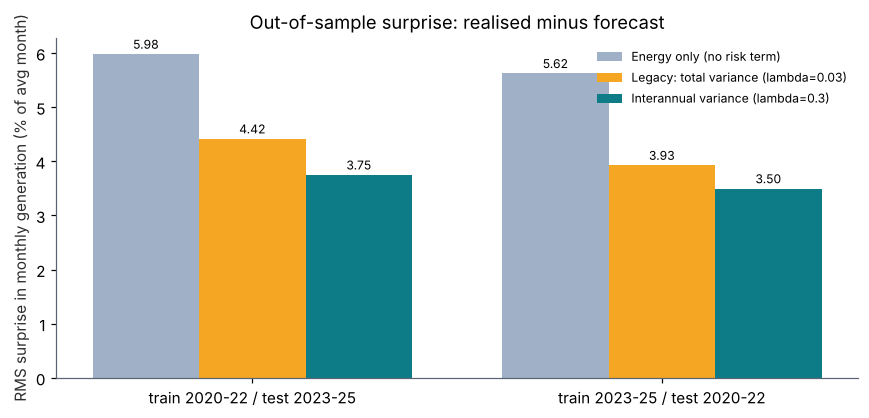

In [12]:
# ---- out-of-sample validation: fit on three years, test on the other three
def year_cols(years): return np.concatenate([np.arange(12 * (y - 2020), 12 * (y - 2020) + 12) for y in years])
folds = [("train 2020-22 / test 2023-25", [2020, 2021, 2022], [2023, 2024, 2025]),
         ("train 2023-25 / test 2020-22", [2023, 2024, 2025], [2020, 2021, 2022])]
cfgs = {"Energy only (no risk term)": NO_RISK,
        f"Legacy: total variance (lambda={LAM_LEGACY})": dict(i=0.0, s=0.0, t=LAM_LEGACY),
        f"Interannual variance (lambda={LAM})": RISK}
rows = []
for fname, tr, te in folds:
    Etr, Ete = E_hard[:, year_cols(tr)], E_hard[:, year_cols(te)]; rm_tr = RiskModel(Etr)
    for cname, risk in cfgs.items():
        h = solve_miqp(rm_tr, risk); x = h["x"]
        fc = rm_tr.M.T @ x                                          # forecast of each calendar month from the training years
        real = (Ete.T @ x).reshape(len(te), 12)                     # realised generation in the unseen years
        err = real - fc[None, :]
        rows.append(dict(fold=fname, plan=cname, plants=int(h["y"].sum()), forecast_GWh=float(rm_tr.ebar @ x), realised_GWh=float(real.sum() / len(te)),
                         monthly_surprise_pct=float(100 * np.sqrt((err ** 2).mean()) / fc.mean()),
                         annual_surprise_pct=float(100 * np.sqrt(((real.sum(1) - fc.sum()) ** 2).mean()) / fc.sum()),
                         worst_year_vs_forecast_pct=float(100 * (real.sum(1).min() / fc.sum() - 1))))
oos = pd.DataFrame(rows); display(oos.round(2))

fig, ax = plt.subplots(figsize=(8.0, 3.9)); w = 0.26
for k, (cname, col) in enumerate(zip(cfgs, [GREY, GOLD, TEAL])):
    v = [oos[(oos.fold == f[0]) & (oos.plan == cname)].monthly_surprise_pct.iloc[0] for f in folds]
    ax.bar(np.arange(2) + (k - 1) * w, v, w, color=col, label=cname)
    for i, vv in enumerate(v): ax.text(i + (k - 1) * w, vv + 0.1, f"{vv:.2f}", ha="center", fontsize=8)
ax.set_xticks(range(2)); ax.set_xticklabels([f[0] for f in folds]); ax.set_ylabel("RMS surprise in monthly generation (% of avg month)")
ax.set_title("Out-of-sample surprise: realised minus forecast"); ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.savefig("figures/fig_oos.png", dpi=200); plt.show()

## 10. Summary and caveats

### Findings (numbers from the delivered run; the cell below recomputes them from the live variables)
1. **The easy plan is not implementable.** It claims 34,781 GWh/yr, but with fixed connection charges its 23 plants cost Rs 113,800 crore against a Rs 100,000 crore budget.
2. **Price of realism: 3,820 GWh/yr (11.0% of the claim).** Almost all of it is the cost model (fixed charge and minimum size, -4,094 GWh). The yield model contributes slightly *positively* (+273 GWh) once the optimiser can re-site, so heat and wind de-rating is not what makes the easy plan wrong. The decomposition is order-independent (two-factor Shapley).
3. **Re-siting matters.** Only 11 of the easy plan's 23 sites survive. Under the full objective the hard plan beats the easy plan's sites resized to the budget by 1,846 objective units (about 1.0 TWh of energy when both ignore risk).
4. **Price of risk reduction: 754 GWh/yr (2.2% of the claim), a choice.** It cuts interannual std from 130 to 73 GWh and the year-to-year CV from 1.26% to 1.14%. The benefit is modest because only about 13% of monthly variance is year-to-year deviation to begin with.
5. **The risk definition changes the answer.** The first version's total-variance penalty gives a plan with a year-to-year CV of 1.56%, worse than having no risk term (1.26%), while flattening the seasons. The interannual penalty is better on genuine risk (1.14%) and on energy (30,207 vs 29,965 GWh), but leaves more seasonal swing (std 401 vs 303 GWh).
6. **Geography is driven by the risk term.** The easy plan puts 16 GW in Rajasthan-Gujarat. The hard plan without risk puts 9.6 GW there and 8 GW in the Himalayan cells. With the interannual penalty it is 6 GW Rajasthan-Gujarat, 3.8 GW Himalayan and 8.7 GW South.
7. **Out-of-sample, the interannual plan has the smallest forecast surprise in both folds** (monthly RMS surprise 3.75% and 3.50%, against 5.98% and 5.62% for energy-only and 4.42% and 3.93% for the first version's penalty). The energy-only plan also overstated its own forecast by 2.3% when trained on 2020-22.
8. **Verification.** Every MIQP solve closed to a relative gap below $10^{-6}$. The Clarabel re-solve matches SCIP to about $10^{-5}$ GW, and none of the 5,354 swap/add/drop neighbours improves the default solution (best is 0.6 objective units worse).

### Caveats
- **Cost, size and thermal parameters ($c$, $B$, $U$, $F$, $L$, $\delta$, $\eta_0$) are assumptions**, not dataset values. $\delta$ cannot be estimated because the data have no daily maximum or minimum temperature.
- **$\lambda$ is a judgement.** The default $\lambda=0.3$ sits mid-frontier. Section 8 shows the whole trade-off, and a different $\lambda$ gives a different plan.
- **NASA POWER values are reanalysis/satellite estimates on 0.5-1 degree cells**, not station measurements, and the six-year record is short. The out-of-sample test uses only 3 + 3 years in two folds, so it is evidence, not proof.
- **Not modelled:** transmission and curtailment, land availability, snow and ice, soiling and degradation, panel tilt (GHI is used, not plane-of-array irradiance), and site-to-site correlation beyond what the six years reveal.
- **Region groups** are latitude-longitude boxes, not state borders. The India filter uses cell centres, so a few border cells may be misclassified.

In [13]:
# ---- headline numbers recomputed from the live variables, and files saved for the report/slides
pe, ph, pd_ = metrics(x_easy), metrics(x_hard), metrics(D["x"])
print(f"Easy LP     : claims {obj_easy:,.0f} GWh/yr | real yield {pe['energy']:,.0f} | cost with fixed charges {pe['cost']:,.0f} vs budget {BUDGET:,.0f} | {pe['plants']} plants")
print(f"Hard MIQP   : {ph['energy']:,.0f} GWh/yr | {ph['plants']} plants, {ph['capacity']:.2f} GW | interannual std {ph['std_inter']:.1f} GWh | year CV {ph['cv_years_pct']:.2f}% | seasonal std {ph['std_seas']:.1f} GWh")
print(f"Price of realism      : {price_real:,.0f} GWh ({100 * price_real / obj_easy:.1f}%)  [yield {y_eff:+,.0f}, cost {c_eff:+,.0f}]")
print(f"Price of risk reduction: {price_risk:,.0f} GWh ({100 * price_risk / obj_easy:.1f}%); CV {pd_['cv_years_pct']:.2f}% -> {ph['cv_years_pct']:.2f}%")
print(f"Verification: gap {H['gap']:.1e}; Clarabel diff {abs(obj_qp - H['obj']):.1e}; {n_moves} neighbours, best {best_nb:,.4f} vs {H['obj']:,.4f}")

results = dict(
    settings=dict(ETA0=ETA0, GAMMA=GAMMA, U0=U0, U1=U1, SUN_HOURS=SUN_HOURS, DELTA_T=DELTA_T, PHI_MAX=PHI_MAX, C0=C0, BUDGET=BUDGET, UCAP=UCAP, FIXED=FIXED, LMIN=LMIN,
                  LAM=LAM, MU=MU, THETA=THETA, PR_easy=PR_easy, n_sites=n),
    easy=dict(claimed_GWh=obj_easy, budget_dual=dual_easy, real=pe),
    hard=dict(plan=ph, objective=H["obj"], gap=H["gap"], bound=H["bound"], regions=reg_gw(x_hard)),
    hard_no_risk=dict(plan=pd_, regions=reg_gw(D["x"])),
    realism=dict(corners=corner, yield_effect=y_eff, cost_effect=c_eff, price_of_realism=price_real, price_of_risk_reduction=price_risk),
    verification=dict(clarabel_diff=abs(obj_qp - H["obj"]), neighbours=n_moves, best_neighbour=best_nb),
    sweeps=sweeps, out_of_sample=oos.to_dict("records"))
with open("results.json", "w") as f: json.dump(results, f, indent=2, default=float)
out = sites.copy(); out["easy_GW"] = x_easy; out["hard_no_risk_GW"] = D["x"]; out["hard_GW"] = x_hard
out["yield_easy_GWh_per_GW"] = ebar_easy; out["yield_hard_GWh_per_GW"] = ebar_hard
out.to_csv("site_results.csv", index=False)
print("\nsaved: results.json, site_results.csv, figures:", ", ".join(sorted(os.listdir("figures"))))

Easy LP     : claims 34,781 GWh/yr | real yield 34,652 | cost with fixed charges 113,800 vs budget 100,000 | 23 plants
Hard MIQP   : 30,207 GWh/yr | 20 plants, 19.56 GW | interannual std 73.3 GWh | year CV 1.14% | seasonal std 400.9 GWh
Price of realism      : 3,820 GWh (11.0%)  [yield +273, cost -4,094]
Price of risk reduction: 754 GWh (2.2%); CV 1.26% -> 1.14%
Verification: gap 0.0e+00; Clarabel diff 6.1e-06; 5354 neighbours, best 28,594.2942 vs 28,594.8900

saved: results.json, site_results.csv, figures: fig_budget.png, fig_candidates.png, fig_firm_fixed.png, fig_fixed_charge.png, fig_lambda.png, fig_maps.png, fig_monthly_series.png, fig_oos.png, fig_profile.png, fig_regions.png, fig_sorted_yield.png, fig_variance_split.png, fig_waterfall.png, fig_years.png, fig_yield.png
